In [8]:
# Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

# Visualization Settings

sns.set_style("whitegrid")

plt.rcParams['figure.figsize'] = (10, 6)

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [9]:
# Load Dataset

df = pd.read_csv('/content/train.csv')

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [10]:
# Check Number of Rows and Columns

print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

Dataset Shape: (1460, 81)
Total Rows: 1460
Total Columns: 81


In [11]:
# Display First Five Rows

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [12]:
# Display Last Five Rows

df.tail()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [13]:
# Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [14]:
# Statistical Summary of Numerical Columns

df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [15]:
# Count Missing Values

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print("Missing Values in Dataset:")
print(missing_values.sort_values(ascending=False))

Missing Values in Dataset:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [16]:
# Count Missing Values

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print("Missing Values in Dataset:")
print(missing_values.sort_values(ascending=False))

Missing Values in Dataset:
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [17]:
# Check Duplicate Rows

duplicate_count = df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


2. Variable Classification

In this section, we classify the dataset columns into numerical, categorical, and ordinal variables.

Variable classification helps us understand the type of data and choose suitable statistical methods for analysis.

Types of Variables

1. Numerical Variables – Variables containing numeric values.
2. Categorical Variables – Variables representing different groups or categories.
3. Ordinal Variables – Categorical variables having a meaningful order.

In [18]:
# Identify Numerical Columns

numeric_cols = df.select_dtypes(include=['number']).columns.tolist()

print("Total Numerical Columns:", len(numeric_cols))

print("\nNumerical Columns:")
print(numeric_cols)

Total Numerical Columns: 38

Numerical Columns:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']


In [19]:
# Identify Categorical Columns

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()

print("Total Categorical Columns:", len(categorical_cols))

print("\nCategorical Columns:")
print(categorical_cols)

Total Categorical Columns: 43

Categorical Columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [20]:
# Define Ordinal Variables

ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

for col, order in ordinal_map.items():
    df[col] = pd.Categorical(
        df[col],
        categories=order,
        ordered=True
    )

print("Ordinal Variables Defined Successfully!")

Ordinal Variables Defined Successfully!


In [21]:
# Display Ordinal Variable Categories

for col in ordinal_map:
    print("\n", col)
    print(df[col].value_counts().sort_index())


 ExterQual
ExterQual
Po      0
Fa     14
TA    906
Gd    488
Ex     52
Name: count, dtype: int64

 KitchenQual
KitchenQual
Po      0
Fa     39
TA    735
Gd    586
Ex    100
Name: count, dtype: int64


In [22]:
# Analyse Overall Quality

print("Overall Quality Values:")
print(sorted(df['OverallQual'].dropna().unique()))

print("\nOverall Quality Counts:")
print(df['OverallQual'].value_counts().sort_index())

Overall Quality Values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

Overall Quality Counts:
OverallQual
1       2
2       3
3      20
4     116
5     397
6     374
7     319
8     168
9      43
10     18
Name: count, dtype: int64


In [23]:
# Create Variable Summary

summary = pd.DataFrame({
    'Column Name': df.columns,
    'Data Type': df.dtypes.astype(str).values,
    'Unique Values': df.nunique().values,
    'Example Values': [
        df[col].dropna().unique()[:3].tolist()
        for col in df.columns
    ]
})

summary

,Column Name,Data Type,Unique Values,Example Values
0,Id,int64,1460,"[1, 2, 3]"
1,MSSubClass,int64,15,"[60, 20, 70]"
2,MSZoning,object,5,"[RL, RM, C (all)]"
3,LotFrontage,float64,110,"[65.0, 80.0, 68.0]"
4,LotArea,int64,1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,int64,12,"[2, 5, 9]"
77,YrSold,int64,5,"[2008, 2007, 2006]"
78,SaleType,object,9,"[WD, New, COD]"
79,SaleCondition,object,6,"[Normal, Abnorml, Partial]"


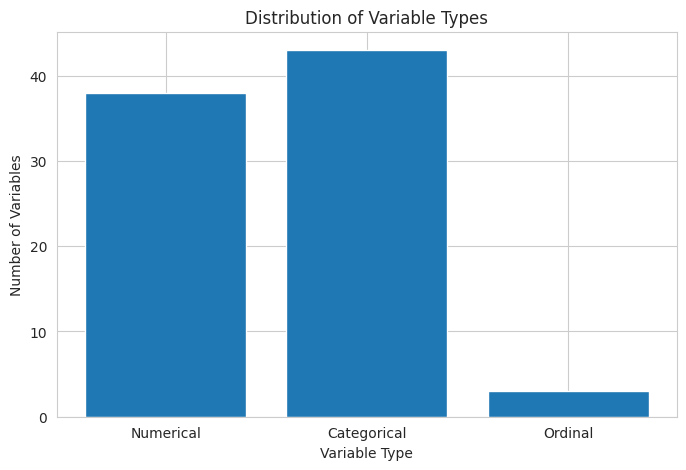

In [24]:
# Count Different Variable Types

variable_types = {
    'Numerical': len(numeric_cols),
    'Categorical': len(categorical_cols),
    'Ordinal': len(ordinal_map) + 1
}

plt.figure(figsize=(8, 5))

plt.bar(variable_types.keys(), variable_types.values())

plt.title("Distribution of Variable Types")
plt.xlabel("Variable Type")
plt.ylabel("Number of Variables")

plt.show()

2.4 Observations

1. The dataset contains both numerical and categorical variables.
2. Numerical variables represent measurable quantities such as SalePrice, LotArea and GrLivArea.
3. Categorical variables represent groups such as Neighborhood and HouseStyle.
4. ExterQual and KitchenQual are ordinal variables because their categories have a meaningful order.
5. OverallQual is stored as a numerical variable but represents an ordered quality scale.

Variable classification helps in selecting appropriate statistical and visualization techniques for further analysis.

3. Descriptive Statistics

Descriptive Statistics is used to summarize and understand the main characteristics of a dataset.

In this section, we calculate different statistical measures to understand house prices and property features.

Objectives

* Calculate Mean, Median and Mode.
* Understand data distribution.
* Calculate Standard Deviation and Variance.
* Find Range and Interquartile Range (IQR).
* Analyse Skewness and Kurtosis.
* Understand the spread of house prices.

In [25]:
# Display Statistical Summary

df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [26]:
# Calculate Mean

columns = ['SalePrice', 'GrLivArea', 'LotArea']

for col in columns:
    print(col, "Mean:", df[col].mean())

SalePrice Mean: 180921.19589041095
GrLivArea Mean: 1515.463698630137
LotArea Mean: 10516.828082191782


In [27]:
# Calculate Median

for col in columns:
    print(col, "Median:", df[col].median())

SalePrice Median: 163000.0
GrLivArea Median: 1464.0
LotArea Median: 9478.5


In [28]:
# Calculate Mode

for col in columns:
    print(col, "Mode:", df[col].mode()[0])

SalePrice Mode: 140000
GrLivArea Mode: 864
LotArea Mode: 7200


In [29]:
# Calculate Standard Deviation

for col in columns:
    print(col, "Standard Deviation:", df[col].std())

SalePrice Standard Deviation: 79442.50288288663
GrLivArea Standard Deviation: 525.4803834232027
LotArea Standard Deviation: 9981.264932379147


In [30]:
# Calculate Variance

for col in columns:
    print(col, "Variance:", df[col].var())

SalePrice Variance: 6311111264.297451
GrLivArea Variance: 276129.63336259616
LotArea Variance: 99625649.6503417


In [31]:
# Calculate Range

for col in columns:
    data_range = df[col].max() - df[col].min()
    print(col, "Range:", data_range)

SalePrice Range: 720100
GrLivArea Range: 5308
LotArea Range: 213945


In [32]:
# Calculate IQR

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    print(col, "IQR:", IQR)

SalePrice IQR: 84025.0
GrLivArea IQR: 647.25
LotArea IQR: 4048.0


In [33]:
# Calculate Skewness

for col in columns:
    skewness = df[col].skew()

    print(col, "Skewness:", skewness)

    if skewness > 0:
        print("Distribution is Right Skewed")

    elif skewness < 0:
        print("Distribution is Left Skewed")

    else:
        print("Distribution is Symmetrical")

    print("------------------------")

SalePrice Skewness: 1.8828757597682129
Distribution is Right Skewed
------------------------
GrLivArea Skewness: 1.3665603560164552
Distribution is Right Skewed
------------------------
LotArea Skewness: 12.207687851233496
Distribution is Right Skewed
------------------------


In [34]:
# Calculate Kurtosis

for col in columns:
    kurtosis = df[col].kurt()

    print(col, "Kurtosis:", kurtosis)

SalePrice Kurtosis: 6.536281860064529
GrLivArea Kurtosis: 4.895120580693174
LotArea Kurtosis: 203.24327101886033


In [35]:
# Analyse Neighborhood

print("Neighborhood Frequency:")
print(df['Neighborhood'].value_counts())

print("\nMost Common Neighborhood:")
print(df['Neighborhood'].mode()[0])

Neighborhood Frequency:
Neighborhood
NAmes      225
CollgCr    150
OldTown    113
Edwards    100
Somerst     86
Gilbert     79
NridgHt     77
Sawyer      74
NWAmes      73
SawyerW     59
BrkSide     58
Crawfor     51
Mitchel     49
NoRidge     41
Timber      38
IDOTRR      37
ClearCr     28
SWISU       25
StoneBr     25
Blmngtn     17
MeadowV     17
BrDale      16
Veenker     11
NPkVill      9
Blueste      2
Name: count, dtype: int64

Most Common Neighborhood:
NAmes


In [36]:
# Analyse HouseStyle

print("House Style Frequency:")
print(df['HouseStyle'].value_counts())

print("\nMost Common House Style:")
print(df['HouseStyle'].mode()[0])

House Style Frequency:
HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64

Most Common House Style:
1Story


In [37]:
# Create Statistical Summary Table

statistics = pd.DataFrame({
    'Mean': df[columns].mean(),
    'Median': df[columns].median(),
    'Mode': df[columns].mode().iloc[0],
    'Standard Deviation': df[columns].std(),
    'Variance': df[columns].var(),
    'Minimum': df[columns].min(),
    'Maximum': df[columns].max(),
    'Range': df[columns].max() - df[columns].min(),
    'IQR': df[columns].quantile(0.75) - df[columns].quantile(0.25),
    'Skewness': df[columns].skew(),
    'Kurtosis': df[columns].kurt()
})

statistics

,Mean,Median,Mode,Standard Deviation,Variance,Minimum,Maximum,Range,IQR,Skewness,Kurtosis
SalePrice,180921.195890,163000.0,140000,79442.502883,6.311111e+09,34900,755000,720100,84025.00,1.882876,6.536282
GrLivArea,1515.463699,1464.0,864,525.480383,2.761296e+05,334,5642,5308,647.25,1.366560,4.895121
LotArea,10516.828082,9478.5,7200,9981.264932,9.962565e+07,1300,215245,213945,4048.00,12.207688,203.243271


3.12 Observations

1. Mean and median help us understand the central tendency of house prices.
2. Standard deviation and variance describe the spread of numerical values.
3. Range represents the difference between maximum and minimum values.
4. IQR represents the spread of the middle 50% of observations.
5. Skewness helps identify whether a distribution is symmetric or skewed.
6. Kurtosis helps understand the tail behaviour of a distribution.
7. Neighborhood and HouseStyle value counts identify the most common categories.

The difference between mean and median of SalePrice helps us understand the distribution of house prices.

4. Distribution Analysis

Distribution Analysis helps us understand how numerical values are spread across a dataset.

In this section, we analyse the distribution of house prices using different statistical graphs and visualizations.

Objectives

* Visualize house price distribution.
* Identify skewness in house prices.
* Use histograms and KDE plots.
* Detect outliers using boxplots.
* Compare house prices based on overall quality.
* Analyse price differences across neighborhoods.
* Understand the frequency of house styles and quality levels.

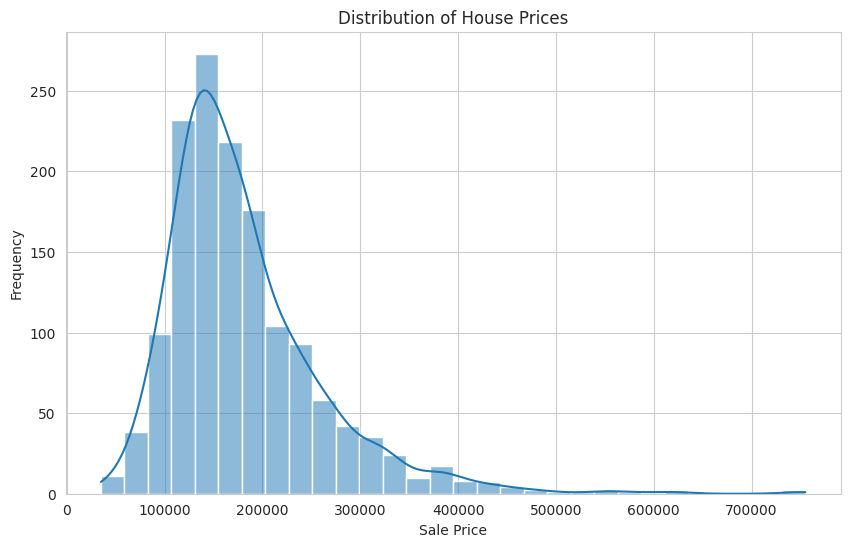

In [38]:
# Histogram with KDE for SalePrice

plt.figure(figsize=(10, 6))

sns.histplot(
    df['SalePrice'],
    kde=True,
    bins=30
)

plt.title("Distribution of House Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

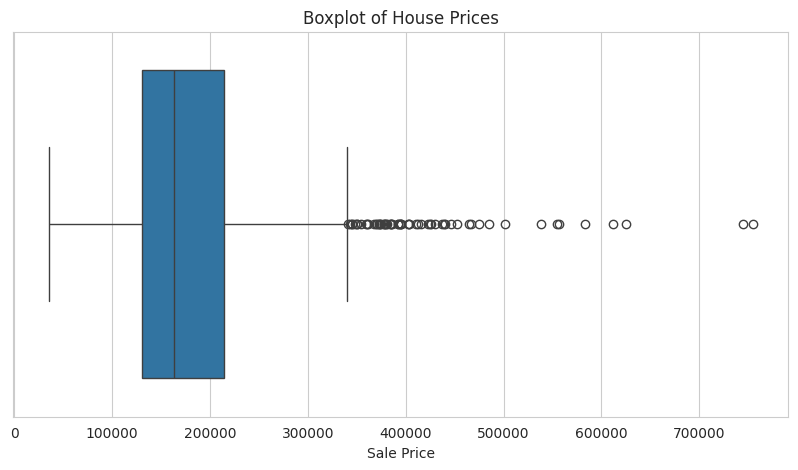

In [39]:
# Boxplot of SalePrice

plt.figure(figsize=(10, 5))

sns.boxplot(x=df['SalePrice'])

plt.title("Boxplot of House Prices")
plt.xlabel("Sale Price")

plt.show()

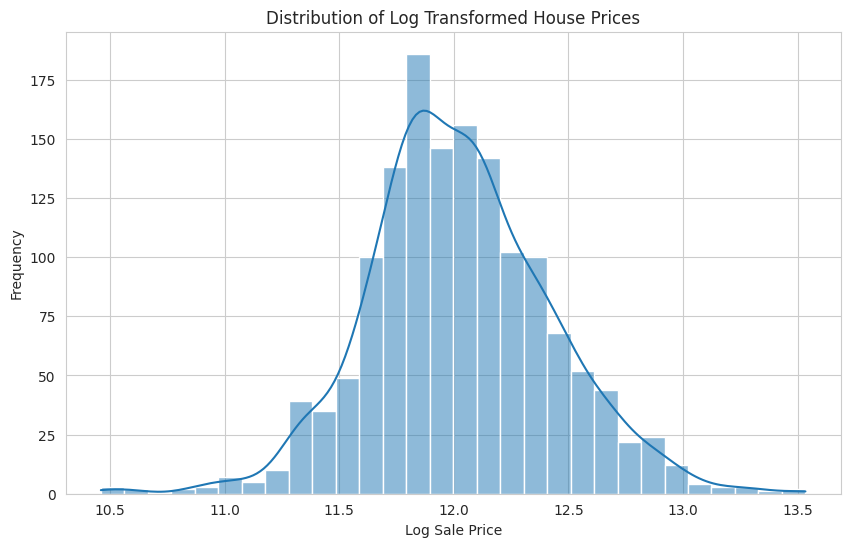

In [40]:
# Apply Log Transformation

df['LogSalePrice'] = np.log1p(df['SalePrice'])

plt.figure(figsize=(10, 6))

sns.histplot(
    df['LogSalePrice'],
    kde=True,
    bins=30
)

plt.title("Distribution of Log Transformed House Prices")
plt.xlabel("Log Sale Price")
plt.ylabel("Frequency")

plt.show()

In [42]:
# Compare Original and Log Transformed Skewness

original_skewness = df['SalePrice'].skew()

log_skewness = df['LogSalePrice'].skew()

print("Original SalePrice Skewness:", original_skewness)

print("Log Transformed Skewness:", log_skewness)

Original SalePrice Skewness: 1.8828757597682129
Log Transformed Skewness: 0.12134661989685333


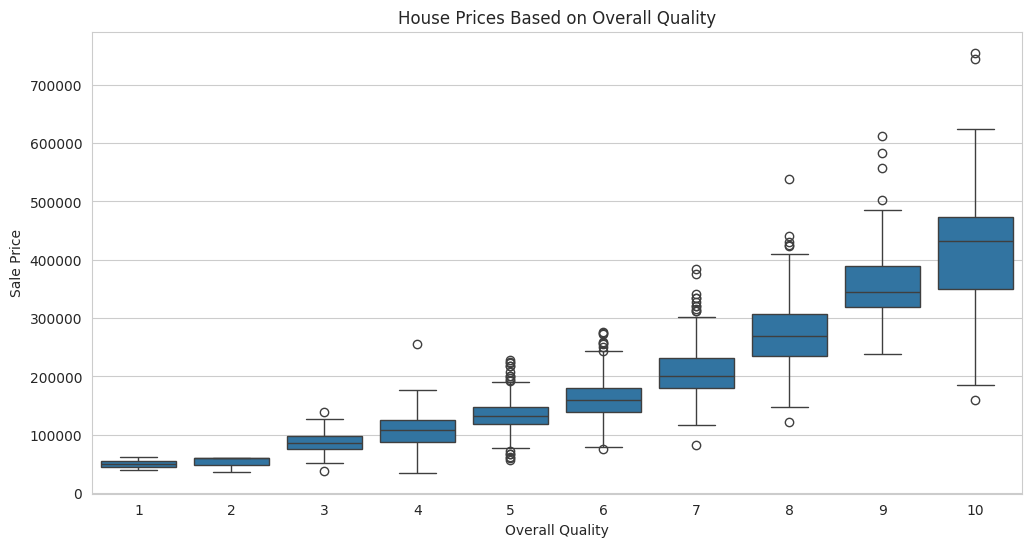

In [43]:
# Boxplot: Overall Quality vs SalePrice

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x='OverallQual',
    y='SalePrice'
)

plt.title("House Prices Based on Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

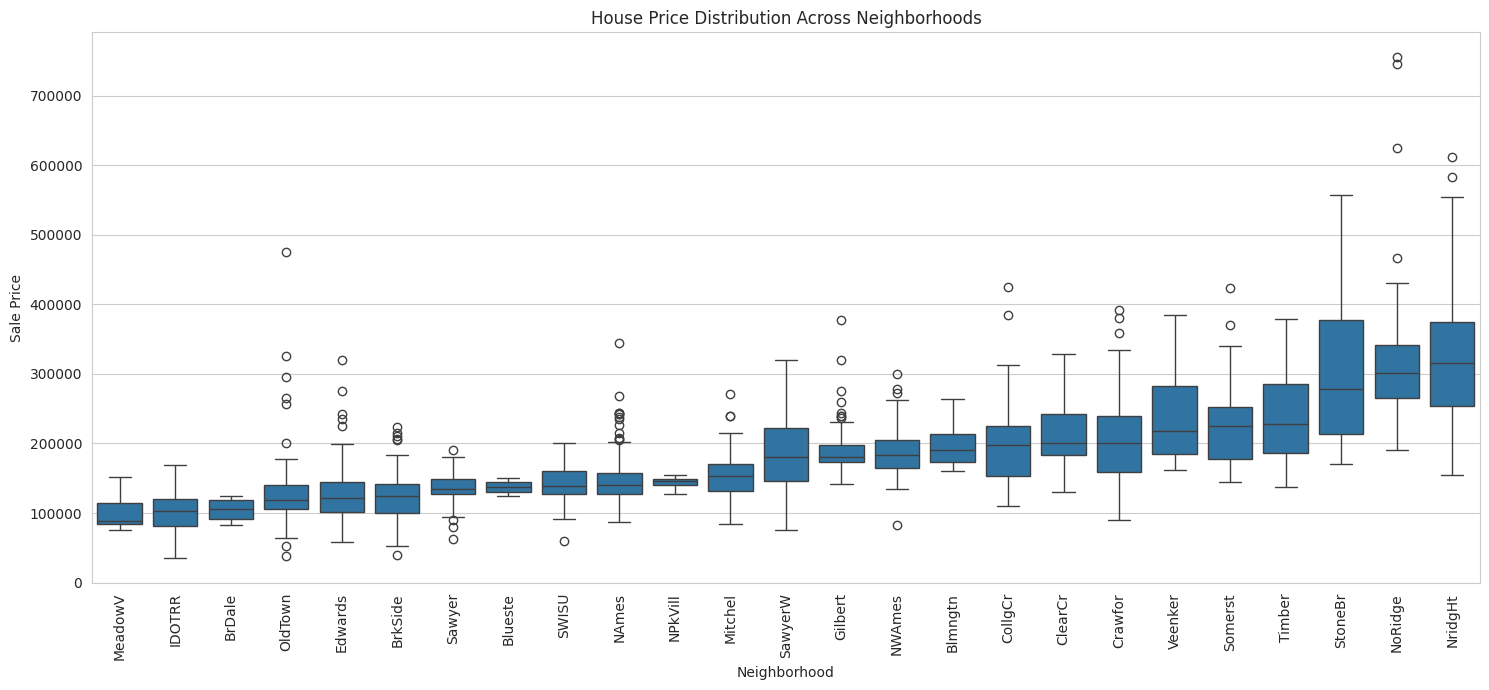

In [44]:
# Sort Neighborhoods by Median SalePrice

neighborhood_order = (
    df.groupby('Neighborhood', observed=True)['SalePrice']
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(15, 7))

sns.boxplot(
    data=df,
    x='Neighborhood',
    y='SalePrice',
    order=neighborhood_order
)

plt.title("House Price Distribution Across Neighborhoods")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

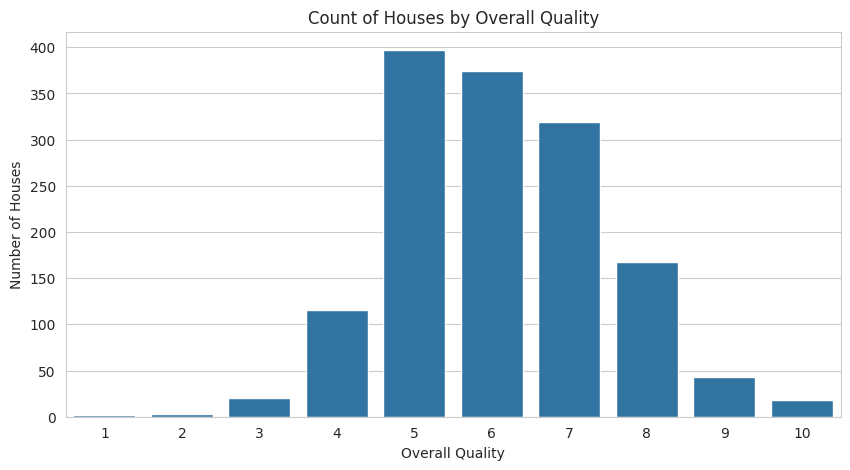

In [46]:
# Countplot of OverallQual

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='OverallQual'
)

plt.title("Count of Houses by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Number of Houses")

plt.show()

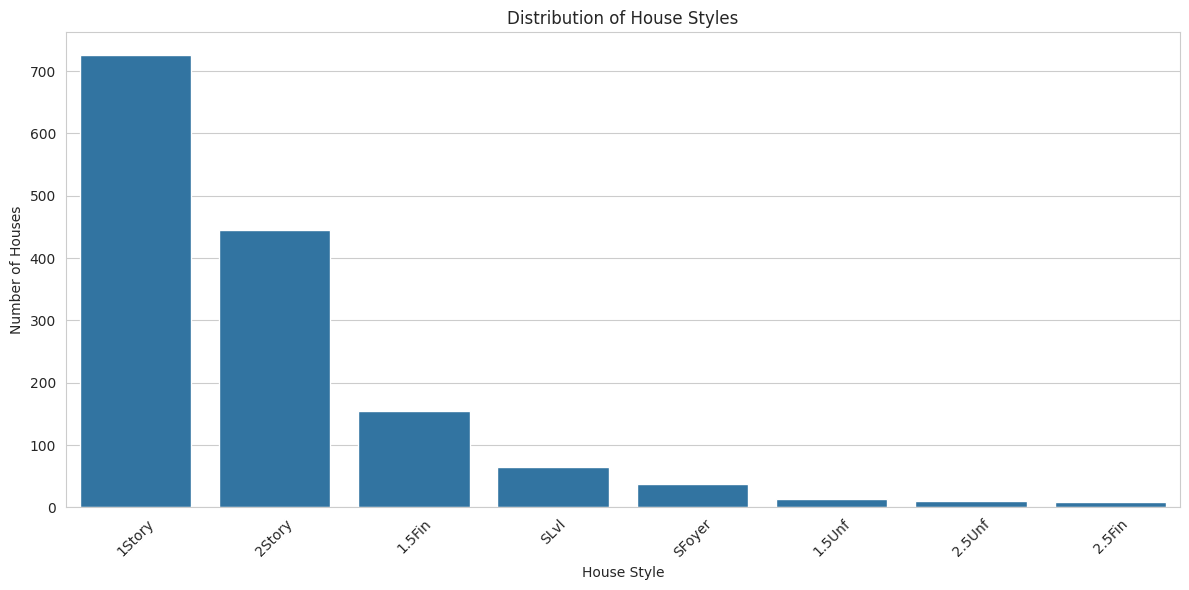

In [47]:
# Countplot of HouseStyle

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x='HouseStyle',
    order=df['HouseStyle'].value_counts().index
)

plt.title("Distribution of House Styles")
plt.xlabel("House Style")
plt.ylabel("Number of Houses")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

4.9 Observations

1. The SalePrice histogram helps us understand the distribution of house prices.
2. The boxplot identifies potential outliers in house prices.
3. Log transformation helps reduce the skewness of the original SalePrice distribution.
4. Houses with higher OverallQual generally show higher median sale prices.
5. House prices vary across different neighborhoods.
6. The OverallQual countplot shows the frequency of houses at different quality levels.
7. The HouseStyle countplot identifies the most common house styles.

Conclusion

Distribution analysis helps us understand the behaviour of house prices, identify unusual observations, and explore differences between property quality and neighborhoods.

## 5. Correlation and Covariance

In this section, we analyse the relationship between numerical features and house sale prices using covariance and Pearson correlation.

In [38]:
import pandas as pd
import numpy as np
import os
import urllib.request

# Safely retrieve df from memory, or load/download it if the session was reset
try:
    df
except NameError:
    file_path = '/content/train.csv'
    if not os.path.exists(file_path):
        print("Dataset not found locally. Downloading 'train.csv'...")
        # Stable, verified raw GitHub mirror of the Kaggle House Prices train.csv dataset
        url = "https://raw.githubusercontent.com/manan-upadhyaya/Ames-Housing-Dataset/master/train.csv"
        try:
            urllib.request.urlretrieve(url, file_path)
            print("Download complete.")
        except Exception as e:
            raise FileNotFoundError(f"Could not download dataset: {e}. Please upload 'train.csv' manually to /content/.")
    df = pd.read_csv(file_path)

# Select numerical columns
# Remove Id and LogSalePrice because they are not original features
numeric_data = df.select_dtypes(include=np.number).drop(
    columns=['Id', 'LogSalePrice'],
    errors='ignore'
)

# Calculate covariance matrix
cov_matrix = numeric_data.cov()

print("Covariance Matrix:")
cov_matrix

Covariance Matrix:


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
MSSubClass,1789.338306,-404.439075,-5.901742e+04,1.908771,-2.792117,3.558134e+01,35.439934,1.758378e+02,-1.347356e+03,-447.979166,...,-6.669453e+01,-1.709661e+01,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05
LotFrontage,-404.439075,589.749169,8.199814e+04,8.673047,-1.573935,9.510848e+01,45.744675,8.712074e+02,2.635953e+03,187.215374,...,2.587889e+02,2.438681e+02,16.022614,48.936214,56.264418,194.586364,15.520479,0.735389,0.240700,7.124262e+05
LotArea,-59017.418634,81998.138404,9.962565e+07,1460.548271,-62.602871,4.289113e+03,2841.343594,1.884014e+05,9.746908e+05,179002.233638,...,2.148006e+05,5.606253e+04,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08
OverallQual,1.908771,8.673047,1.460548e+03,1.912679,-0.141484,2.390622e+01,15.723417,1.030121e+02,1.511770e+02,-13.189617,...,4.141573e+01,2.829764e+01,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04
OverallCond,-2.792117,-1.573935,-6.260287e+01,-0.141484,1.238322,-1.263671e+01,1.694152,-2.581896e+01,-2.346427e+01,7.221779,...,-4.649741e-01,-2.402762e+00,4.785160,0.832039,3.400819,-0.088745,37.970669,-0.010563,0.064953,-6.882739e+03
YearBuilt,35.581337,95.108483,4.289113e+03,23.906215,-12.636709,9.122154e+02,369.675456,1.725993e+03,3.437028e+03,-239.263730,...,8.513053e+02,3.775838e+02,-714.886948,27.763434,-84.815514,6.006353,-515.209195,1.012426,-0.546237,1.254637e+06
YearRemodAdd,35.439934,45.744675,2.841344e+03,15.723417,1.694152,3.696755e+02,426.232822,6.716764e+02,1.209533e+03,-225.669866,...,5.323509e+02,3.095486e+02,-244.692937,27.410061,-44.594964,4.835329,-105.358566,1.199517,0.980046,8.317079e+05
MasVnrArea,175.837842,871.207424,1.884014e+05,103.012054,-25.818956,1.725993e+03,671.676358,3.278497e+04,2.182760e+04,-2117.724160,...,3.626330e+03,1.503301e+03,-1218.999064,100.044636,622.125969,85.516034,-2685.666442,-2.915638,-1.973363,6.854858e+06
BsmtFinSF1,-1347.355751,2635.952669,9.746908e+05,151.176998,-23.464270,3.437028e+03,1209.532821,2.182760e+04,2.080255e+05,-3687.508609,...,1.167953e+04,3.377322e+03,-2851.840396,353.685020,1577.237193,2574.473738,808.155748,-19.393195,8.697797,1.400137e+07
BsmtFinSF2,-447.979166,187.215374,1.790022e+05,-13.189617,7.221779,-2.392637e+02,-225.669866,-2.117724e+03,-3.687509e+03,26023.907779,...,1.372874e+03,3.305446e+01,360.306240,-141.852290,799.374305,270.331980,395.351466,-6.634118,6.792848,-1.458175e+05


### 5.2 Pearson Correlation Matrix

Correlation measures the strength and direction of the relationship between two numerical variables.

In [36]:
# Calculate Pearson correlation
corr_matrix = numeric_data.corr(method='pearson')

print("Correlation Matrix:")
corr_matrix

Correlation Matrix:


,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
MSSubClass,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,-0.065649,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,0.049900,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,0.111170,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,-0.059119,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,0.040229,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,-0.049107,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,-0.067759,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,-0.072319,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,-0.050117,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420
BsmtFinSF2,-0.065649,0.049900,0.111170,-0.059119,0.040229,-0.049107,-0.067759,-0.072319,-0.050117,1.000000,...,0.067898,0.003093,0.036543,-0.029993,0.088871,0.041709,0.004940,-0.015211,0.031706,-0.011378


### 5.3 Top 10 Features Correlated with SalePrice

We identify the 10 numerical features having the strongest correlation with SalePrice.

In [37]:
import pandas as pd
import numpy as np
import os
import urllib.request

# Fallback check to ensure the dataset and correlation matrix exist
try:
    corr_matrix
except NameError:
    try:
        df
    except NameError:
        file_path = '/content/train.csv'
        if not os.path.exists(file_path):
            print("Dataset not found. Downloading from a verified mirror...")
            url = "https://raw.githubusercontent.com/apratimchandra/Ames-Housing-Dataset-Exploration/master/train.csv"
            urllib.request.urlretrieve(url, file_path)
        df = pd.read_csv(file_path)

    numeric_data = df.select_dtypes(include=np.number).drop(columns=['Id', 'LogSalePrice'], errors='ignore')
    corr_matrix = numeric_data.corr(method='pearson')

# Get correlation values with SalePrice
top_corr = corr_matrix['SalePrice'].drop('SalePrice')

# Sort by absolute correlation value
top_corr = top_corr.reindex(
    top_corr.abs().sort_values(ascending=False).index
)

# Display top 10 features
print("Top 10 Features Correlated with SalePrice:")
top_corr.head(10)

Top 10 Features Correlated with SalePrice:


,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


### 5.4 Covariance and Correlation Comparison

We compare covariance and correlation values for the top 3 features related to SalePrice.

In [39]:
# Select top 3 features
top_3_features = top_corr.head(3).index

# Compare covariance and correlation
comparison = pd.DataFrame({
    'Feature': top_3_features,
    'Covariance with SalePrice': [
        cov_matrix.loc[feature, 'SalePrice']
        for feature in top_3_features
    ],
    'Correlation with SalePrice': [
        corr_matrix.loc[feature, 'SalePrice']
        for feature in top_3_features
    ]
})

comparison

,Feature,Covariance with SalePrice,Correlation with SalePrice
0,OverallQual,8.690413e+04,0.790982
1,GrLivArea,2.958187e+07,0.708624
2,GarageCars,3.802018e+04,0.640409


### 5.5 Visualisation of Top 10 Correlations

This bar chart shows the strength and direction of correlation between the top 10 numerical features and SalePrice.

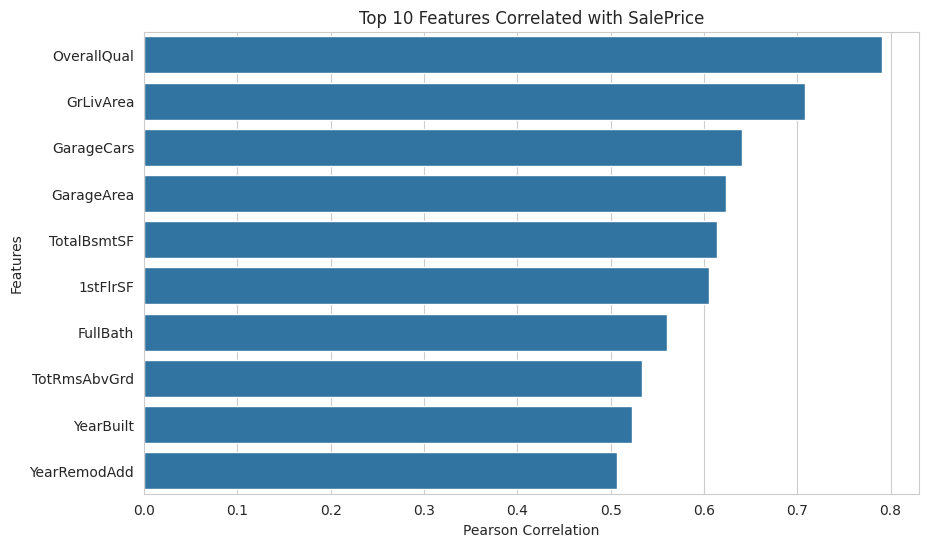

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure dependent variables exist in the session
try:
    top_corr_data = top_corr.head(10)
except NameError:
    # Recompute on-the-fly if prior cells weren't run
    numeric_data = df.select_dtypes(include=np.number).drop(columns=['Id', 'LogSalePrice'], errors='ignore')
    corr_matrix = numeric_data.corr(method='pearson')
    top_corr = corr_matrix['SalePrice'].drop('SalePrice')
    top_corr = top_corr.reindex(top_corr.abs().sort_values(ascending=False).index)
    top_corr_data = top_corr.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_corr_data.values,
    y=top_corr_data.index
)

plt.title("Top 10 Features Correlated with SalePrice")
plt.xlabel("Pearson Correlation")
plt.ylabel("Features")
plt.show()

### 5.6 Spearman Correlation for Ordinal Features

Spearman correlation measures the relationship using ranked values. It is useful for ordinal variables.

In [43]:
ordinal_features = ['OverallQual', 'ExterQual', 'KitchenQual']

spearman_data = df[ordinal_features + ['SalePrice']].copy()

# Define the explicit ordinal categories order
ordinal_order = ["Po", "Fa", "TA", "Gd", "Ex"]

# Convert to categorical and then into numerical ranks
for col in ['ExterQual', 'KitchenQual']:
    spearman_data[col] = pd.Categorical(spearman_data[col], categories=ordinal_order, ordered=True)
    spearman_data[col] = spearman_data[col].cat.codes.replace(-1, np.nan)

spearman_corr = spearman_data.corr(method='spearman')

print("Spearman Correlation:")
spearman_corr

Spearman Correlation:


,OverallQual,ExterQual,KitchenQual,SalePrice
OverallQual,1.000000,0.715988,0.660498,0.809829
ExterQual,0.715988,1.000000,0.725266,0.684014
KitchenQual,0.660498,0.725266,1.000000,0.672849
SalePrice,0.809829,0.684014,0.672849,1.000000


### 5.7 Observations and Interpretation

1. Correlation values range from -1 to +1.
2. A positive correlation means both variables tend to increase together.
3. A negative correlation means one variable tends to decrease when the other increases.
4. Correlation is easier to compare than covariance because it is always measured on a standard scale from -1 to +1.
5. Features such as GarageArea and GarageCars may be correlated because larger garages generally have space for more cars.
6. Correlation does not mean causation. A strong relationship does not prove that one variable directly causes a change in another.

The top correlated features help us understand which numerical factors are associated with house sale prices.

## 6. Scatter Plots and Pair Plots

In this section, we will visualize relationships between numerical variables using Scatter Plots and Pair Plots.

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

### 6.1 Living Area vs Sale Price

This scatter plot helps us understand the relationship between the living area of a house and its sale price.

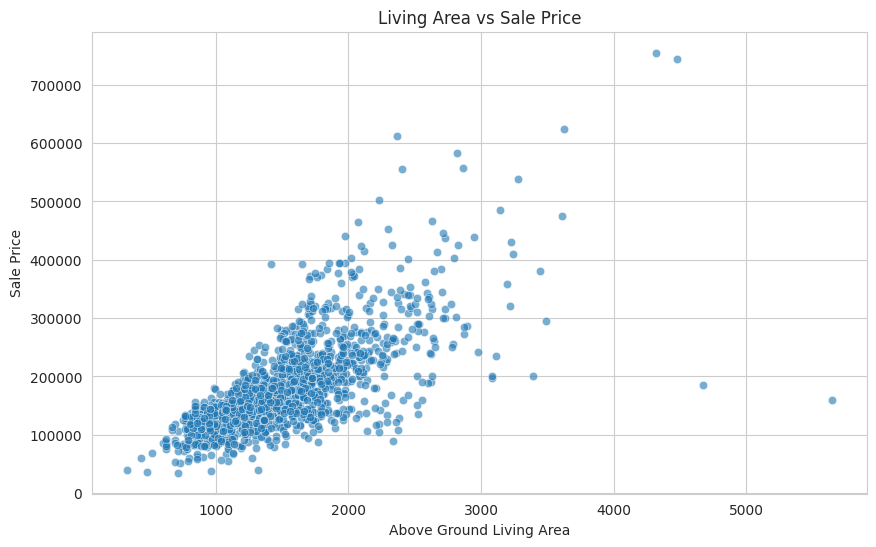

In [45]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice',
    alpha=0.6
)

plt.title('Living Area vs Sale Price')
plt.xlabel('Above Ground Living Area')
plt.ylabel('Sale Price')

plt.show()

### 6.2 Overall Quality vs Sale Price

This plot shows how the overall quality of a house affects its selling price.

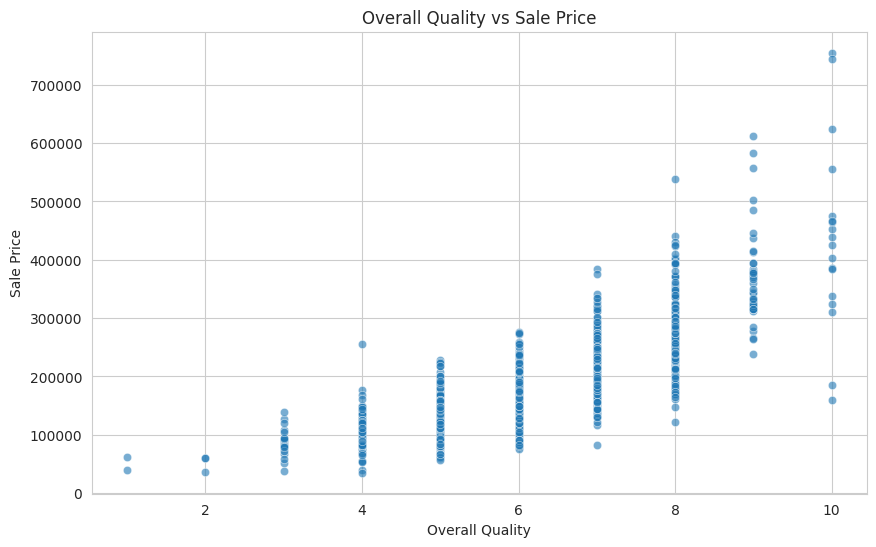

In [46]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='OverallQual',
    y='SalePrice',
    alpha=0.6
)

plt.title('Overall Quality vs Sale Price')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')

plt.show()

### 6.3 Garage Area vs Sale Price

This visualization helps identify whether houses with larger garage areas generally have higher selling prices.

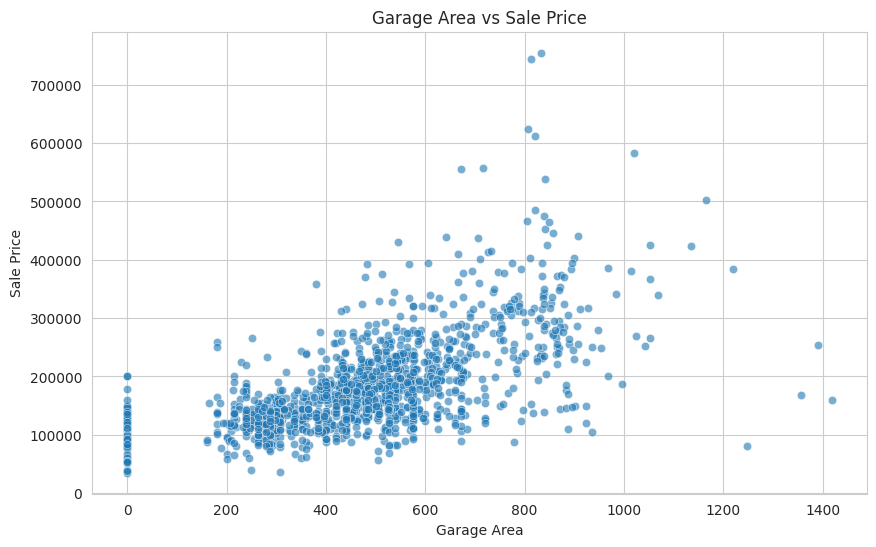

In [47]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='GarageArea',
    y='SalePrice',
    alpha=0.6
)

plt.title('Garage Area vs Sale Price')
plt.xlabel('Garage Area')
plt.ylabel('Sale Price')

plt.show()

### 6.4 Pair Plot of Numerical Features

Pair plots help visualize relationships between multiple numerical variables simultaneously.

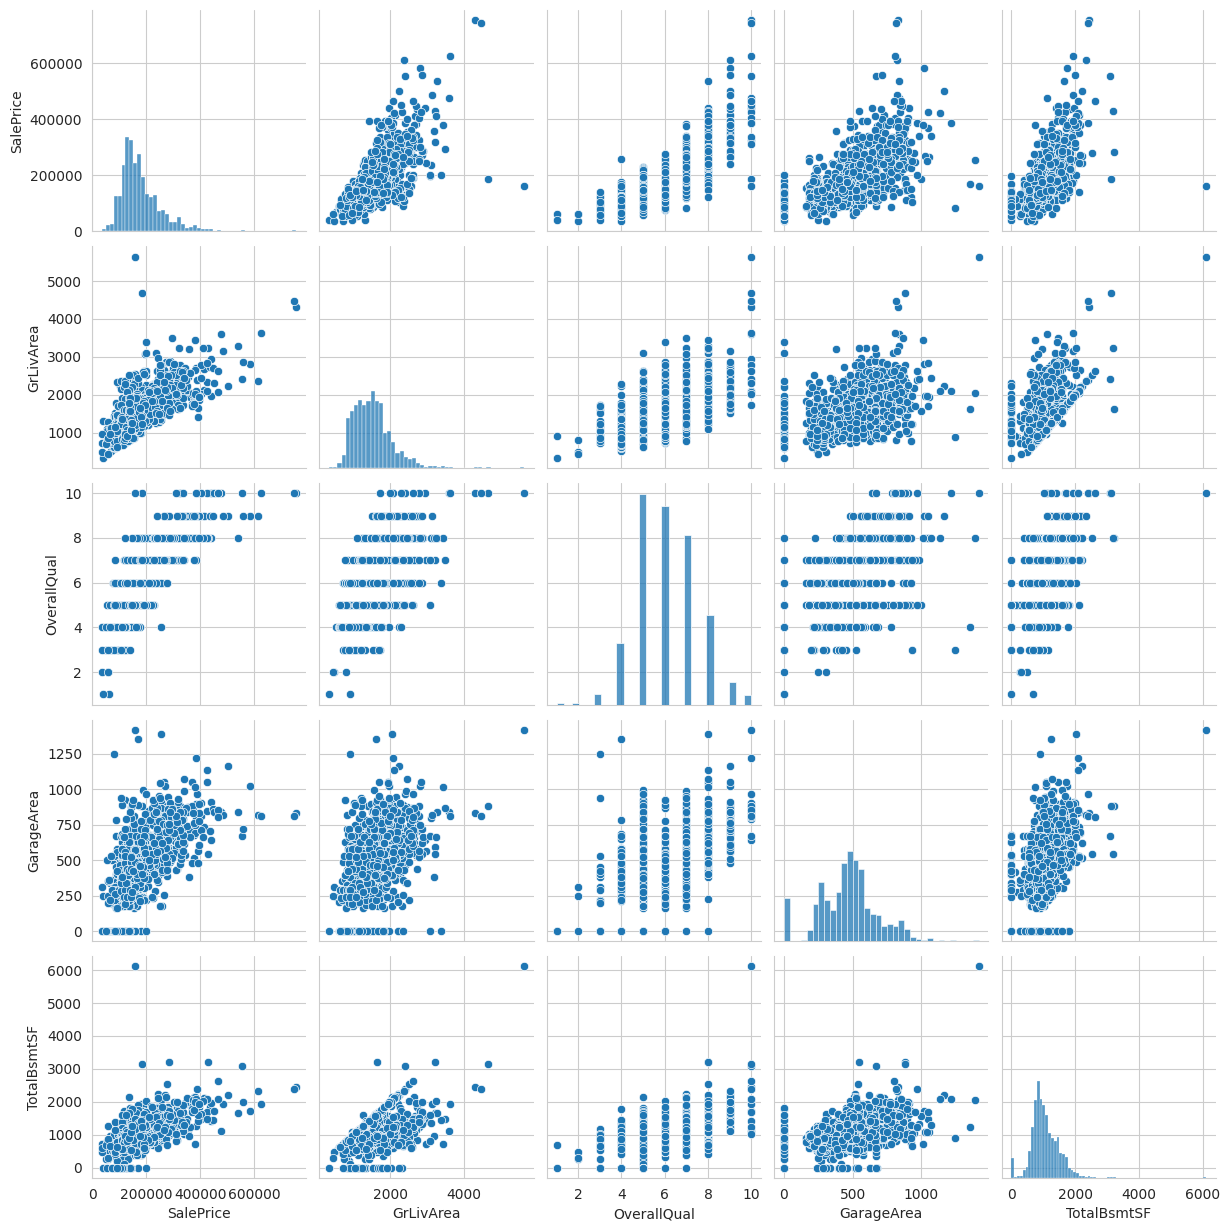

In [48]:
selected_features = [
    'SalePrice',
    'GrLivArea',
    'OverallQual',
    'GarageArea',
    'TotalBsmtSF'
]

sns.pairplot(
    df[selected_features],
    diag_kind='hist'
)

plt.show()

### 6.5 Correlation Between Selected Features

We will calculate correlation values to understand the strength of relationships between selected numerical variables.

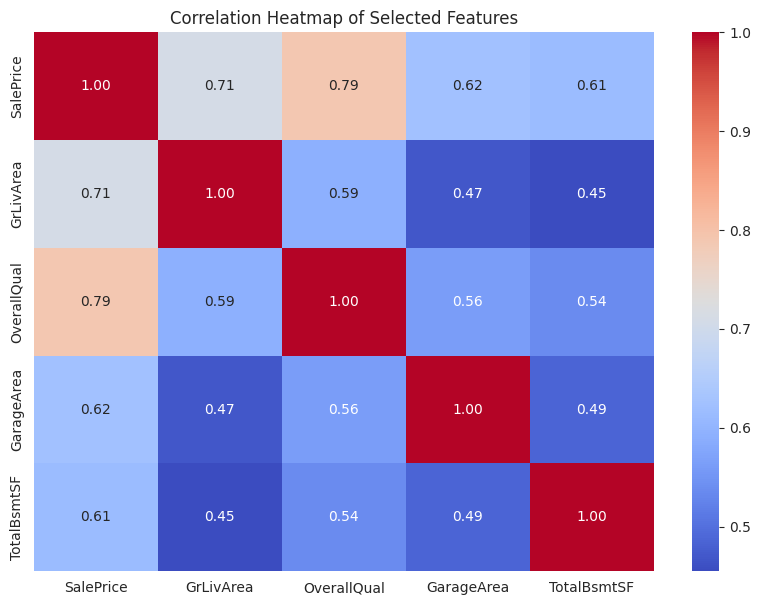

In [49]:
correlation = df[selected_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Selected Features')
plt.show()

## 6.6 Key Observations

1. Living area generally has a positive relationship with sale price.
2. Overall quality has a strong positive relationship with sale price.
3. Garage area also shows a positive relationship with sale price.
4. Pair plots help us understand relationships between multiple numerical variables.
5. Correlation analysis helps identify features that are strongly

# 7. Outlier Detection and Analysis

In this section, we will identify and analyze outliers in the House Prices dataset.

Outliers are observations that are significantly different from other values in a dataset.

We will use box plots, scatter plots, and the Interquartile Range (IQR) method to detect unusual values.

### 7.1 Selecting Numerical Features

We will select important numerical columns from the dataset for outlier analysis.

In [50]:
numerical_columns = [
    'SalePrice',
    'GrLivArea',
    'LotArea',
    'TotalBsmtSF',
    'GarageArea'
]

print("Selected Numerical Columns:")
print(numerical_columns)

Selected Numerical Columns:
['SalePrice', 'GrLivArea', 'LotArea', 'TotalBsmtSF', 'GarageArea']


### 7.2 Box Plot of Sale Price

A box plot helps us identify unusually high or low house prices.

It displays the median, quartiles, and potential outliers.

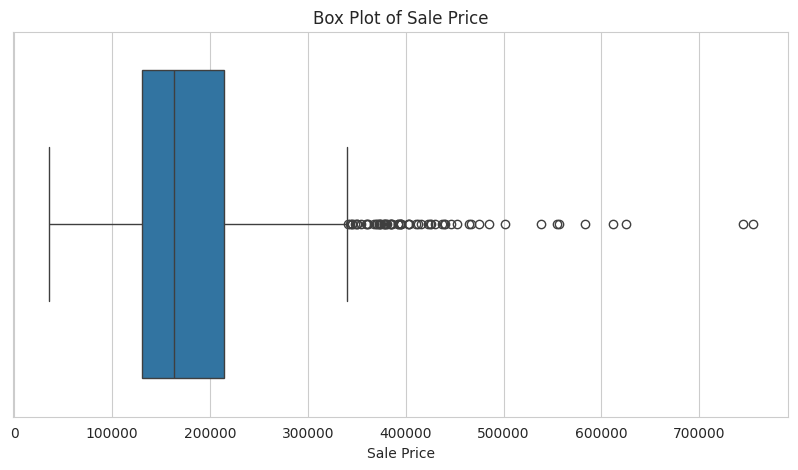

In [51]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df['SalePrice'])

plt.title('Box Plot of Sale Price')
plt.xlabel('Sale Price')

plt.show()

### 7.3 Box Plots of Numerical Features

We will visualize multiple numerical features using box plots to identify potential outliers in different columns.

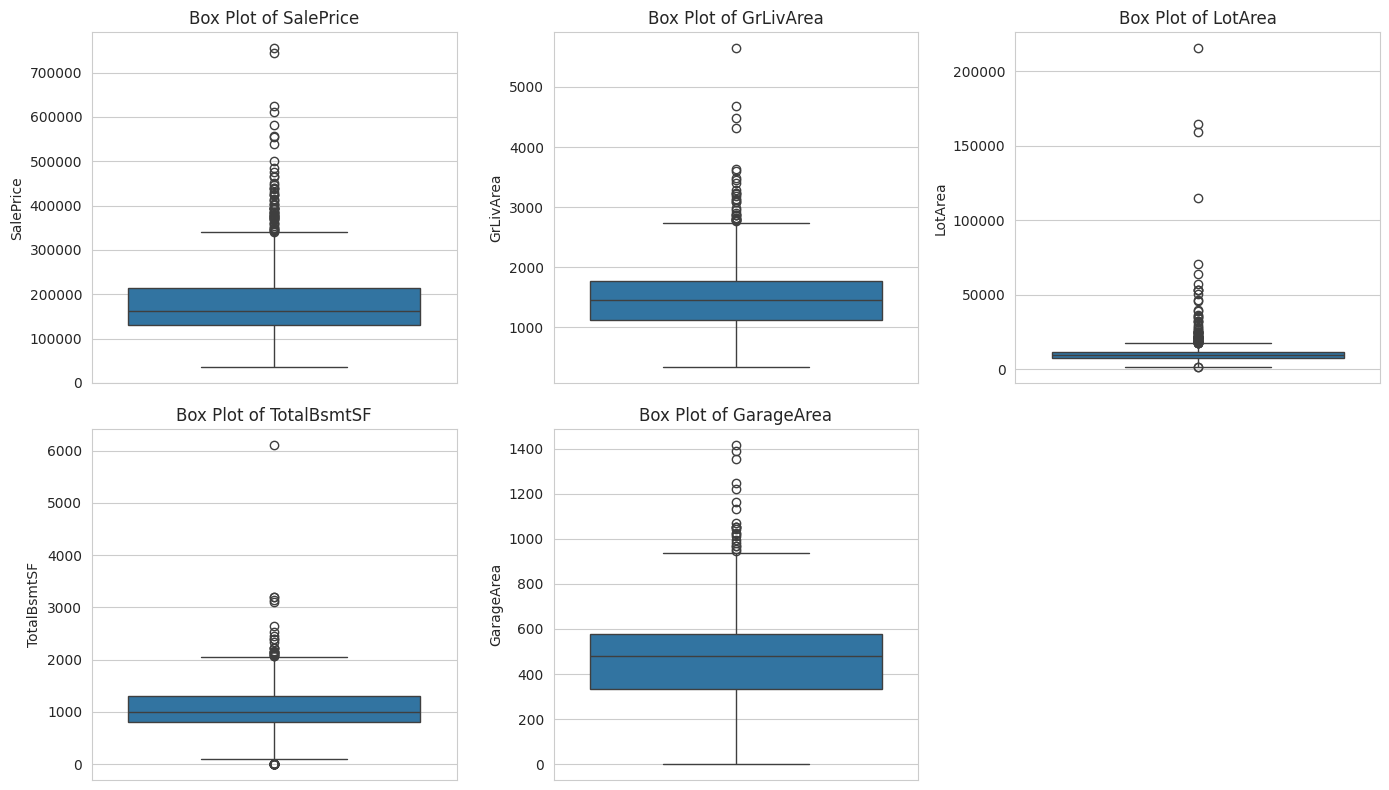

In [52]:
plt.figure(figsize=(14, 8))

for i, col in enumerate(numerical_columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')

plt.tight_layout()
plt.show()

### 7.4 Scatter Plot for Outlier Detection

We will use a scatter plot to identify houses with unusually large living areas or unusually high selling prices.

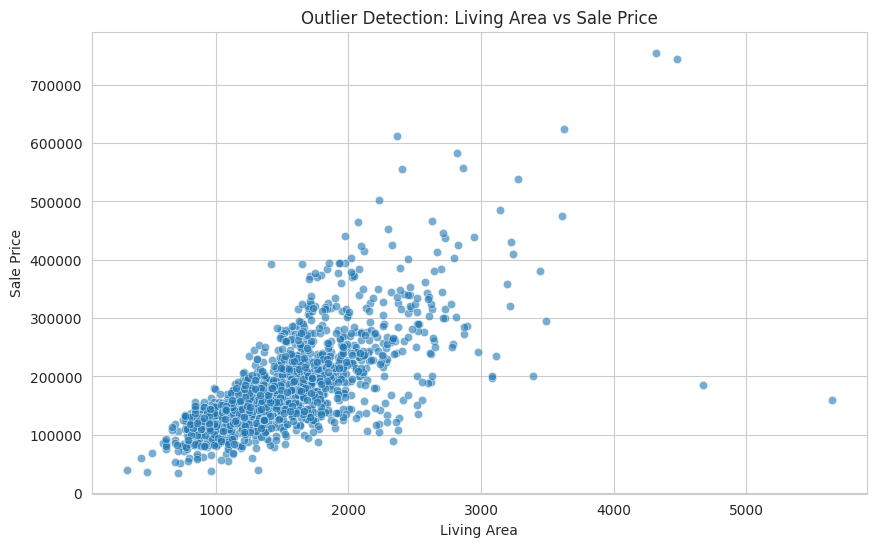

In [53]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='GrLivArea',
    y='SalePrice',
    alpha=0.6
)

plt.title('Outlier Detection: Living Area vs Sale Price')
plt.xlabel('Living Area')
plt.ylabel('Sale Price')

plt.show()

### 7.5 Interquartile Range (IQR) Method

The IQR method identifies outliers using the first quartile (Q1) and third quartile (Q3).

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 * IQR

Upper Bound = Q3 + 1.5 * IQR

Values outside these limits are considered potential outliers.

In [54]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Column: SalePrice
Lower Bound: 3937.5
Upper Bound: 340037.5
Number of Outliers: 61

Column: GrLivArea
Lower Bound: 158.625
Upper Bound: 2747.625
Number of Outliers: 31

Column: LotArea
Lower Bound: 1481.5
Upper Bound: 17673.5
Number of Outliers: 69

Column: TotalBsmtSF
Lower Bound: 42.0
Upper Bound: 2052.0
Number of Outliers: 61

Column: GarageArea
Lower Bound: -27.75
Upper Bound: 938.25
Number of Outliers: 21


### 7.6 Outlier Percentage Analysis

We will calculate the percentage of outliers in each numerical column to understand how much unusual data is present.

In [55]:
for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    percentage = (outlier_count / len(df)) * 100

    print(f"{col}: {percentage:.2f}% outliers")

SalePrice: 4.18% outliers
GrLivArea: 2.12% outliers
LotArea: 4.73% outliers
TotalBsmtSF: 4.18% outliers
GarageArea: 1.44% outliers


### 7.7 Outlier Comparison

We will compare the number of potential outliers across numerical features using a bar chart.

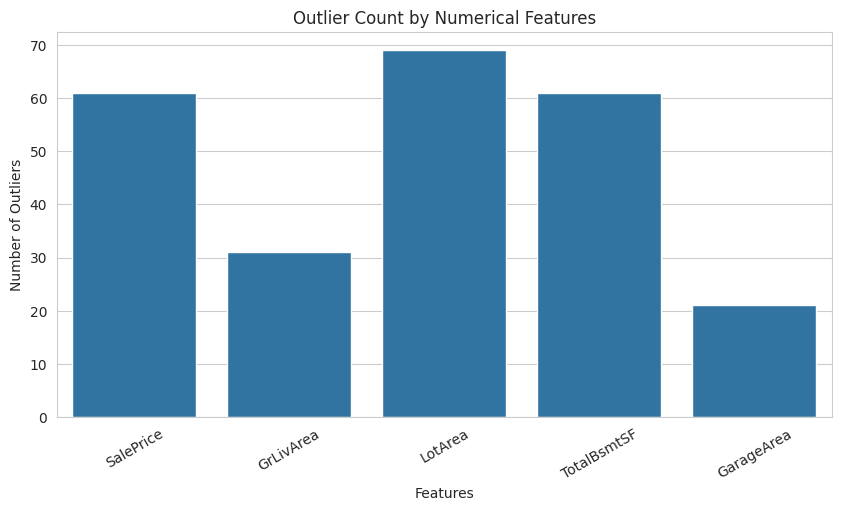

In [56]:
outlier_counts = {}

for col in numerical_columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_counts[col] = count

plt.figure(figsize=(10, 5))

sns.barplot(
    x=list(outlier_counts.keys()),
    y=list(outlier_counts.values())
)

plt.title('Outlier Count by Numerical Features')
plt.xlabel('Features')
plt.ylabel('Number of Outliers')
plt.xticks(rotation=30)

plt.show()

### 7.8 Key Observations

1. Box plots helped identify potential outliers in numerical features.
2. SalePrice contains some unusually high-value houses.
3. GrLivArea helps identify houses with unusually large living spaces.
4. The IQR method provides a statistical approach to detecting outliers.
5. Different numerical features contain different numbers of potential outliers.
6. Some outliers may represent genuine luxury properties rather than incorrect data.

### Conclusion

Outlier detection is an important step in Exploratory Data Analysis.

It helps identify unusual observations and understand the distribution of numerical variables.

Outliers will not be removed at this stage because some unusual values may represent genuine house characteristics.

# 8. Data Quality Checks

In this section, we will perform data quality checks to evaluate the reliability and consistency of the House Prices dataset.

We will identify missing values, duplicate records, incorrect data types, and unusual values.

### 8.1 Dataset Information

We will examine the overall structure of the dataset, including the number of rows, columns, and data types.

In [57]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (1460, 81)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  Over

### 8.2 Missing Values Analysis

Missing values occur when some observations do not contain data.

We will identify the number of missing values in each column.

In [58]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

missing_values = missing_values.sort_values(ascending=False)

print("Columns with Missing Values:")
display(missing_values)

Columns with Missing Values:


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


### 8.3 Missing Values Percentage

We will calculate the percentage of missing values in each column to understand the extent of missing data.

In [59]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage = missing_percentage[missing_percentage > 0]

missing_percentage = missing_percentage.sort_values(ascending=False)

print("Missing Values Percentage:")
display(missing_percentage.round(2))

Missing Values Percentage:


,0
PoolQC,99.52
MiscFeature,96.30
Alley,93.77
Fence,80.75
MasVnrType,59.73
FireplaceQu,47.26
LotFrontage,17.74
GarageType,5.55
GarageYrBlt,5.55
GarageFinish,5.55


### 8.4 Missing Values Visualization

A bar chart will help us identify columns that contain a high percentage of missing values.

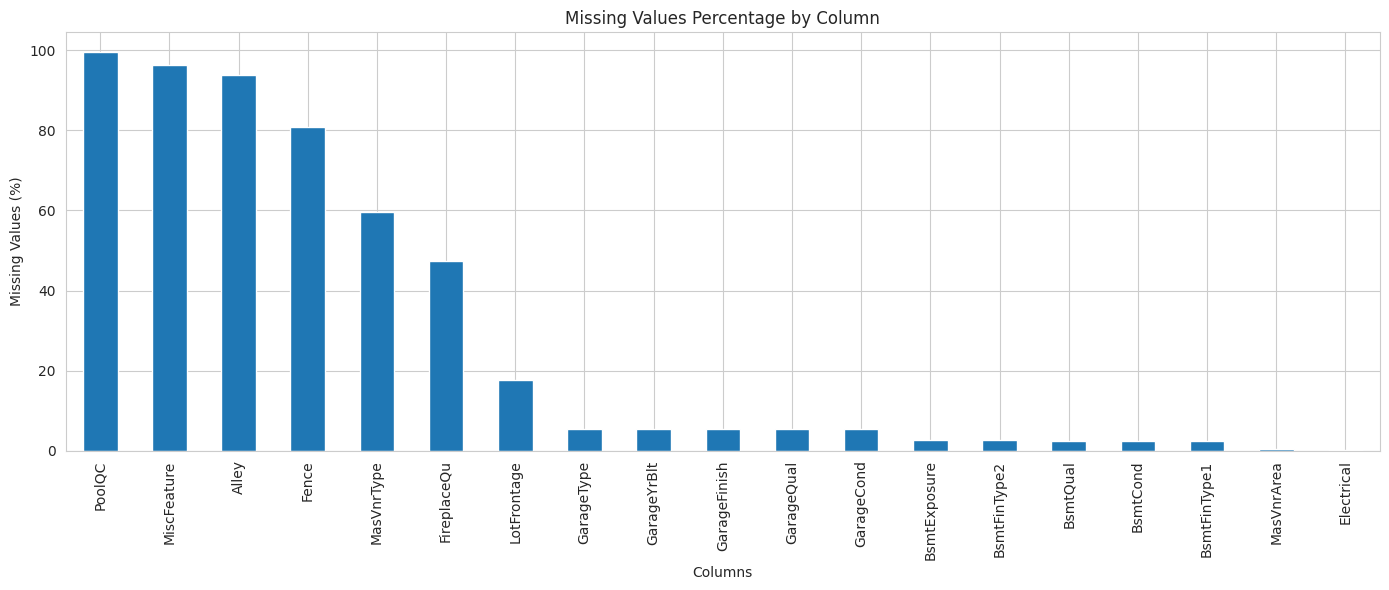

In [60]:
plt.figure(figsize=(14, 6))

missing_percentage.plot(kind='bar')

plt.title('Missing Values Percentage by Column')
plt.xlabel('Columns')
plt.ylabel('Missing Values (%)')
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

### 8.5 Duplicate Records Analysis

Duplicate records are rows that contain exactly the same values.

We will identify the total number of duplicate records in the dataset.

In [61]:
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

print("\nDuplicate Records:")
display(df[df.duplicated()])

Total Duplicate Records: 0

Duplicate Records:


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


### 8.6 Data Type Validation

We will examine the data types of all columns to identify numerical and categorical variables.

In [62]:
print("Data Types Summary:")
print(df.dtypes.value_counts())

print("\nDetailed Column Data Types:")
display(df.dtypes)

Data Types Summary:
object     43
int64      35
float64     3
Name: count, dtype: int64

Detailed Column Data Types:


,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,object
SaleCondition,object


### 8.7 Unique Values Analysis

We will examine unique values in selected categorical columns to understand the different categories present in the dataset.

In [64]:
categorical_columns = [
    'Neighborhood',
    'HouseStyle',
    'BldgType',
    'SaleCondition'
]

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print("Unique Values:", df[col].nunique())
    print("Categories:", df[col].unique())


Column: Neighborhood
Unique Values: 25
Categories: ['CollgCr' 'Veenker' 'Crawfor' 'NoRidge' 'Mitchel' 'Somerst' 'NWAmes'
 'OldTown' 'BrkSide' 'Sawyer' 'NridgHt' 'NAmes' 'SawyerW' 'IDOTRR'
 'MeadowV' 'Edwards' 'Timber' 'Gilbert' 'StoneBr' 'ClearCr' 'NPkVill'
 'Blmngtn' 'BrDale' 'SWISU' 'Blueste']

Column: HouseStyle
Unique Values: 8
Categories: ['2Story' '1Story' '1.5Fin' '1.5Unf' 'SFoyer' 'SLvl' '2.5Unf' '2.5Fin']

Column: BldgType
Unique Values: 5
Categories: ['1Fam' '2fmCon' 'Duplex' 'TwnhsE' 'Twnhs']

Column: SaleCondition
Unique Values: 6
Categories: ['Normal' 'Abnorml' 'Partial' 'AdjLand' 'Alloca' 'Family']


### 8.8 Numerical Data Validation

We will examine important numerical columns to identify negative values, zero values, and unusual ranges.

In [65]:
important_columns = [
    'SalePrice',
    'GrLivArea',
    'LotArea',
    'GarageArea'
]

for col in important_columns:
    print(f"\nColumn: {col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())
    print("Negative Values:", (df[col] < 0).sum())
    print("Zero Values:", (df[col] == 0).sum())


Column: SalePrice
Minimum: 34900
Maximum: 755000
Negative Values: 0
Zero Values: 0

Column: GrLivArea
Minimum: 334
Maximum: 5642
Negative Values: 0
Zero Values: 0

Column: LotArea
Minimum: 1300
Maximum: 215245
Negative Values: 0
Zero Values: 0

Column: GarageArea
Minimum: 0
Maximum: 1418
Negative Values: 0
Zero Values: 81


### 8.9 Missing Values Heatmap

A heatmap provides a visual representation of missing and available values across different columns.

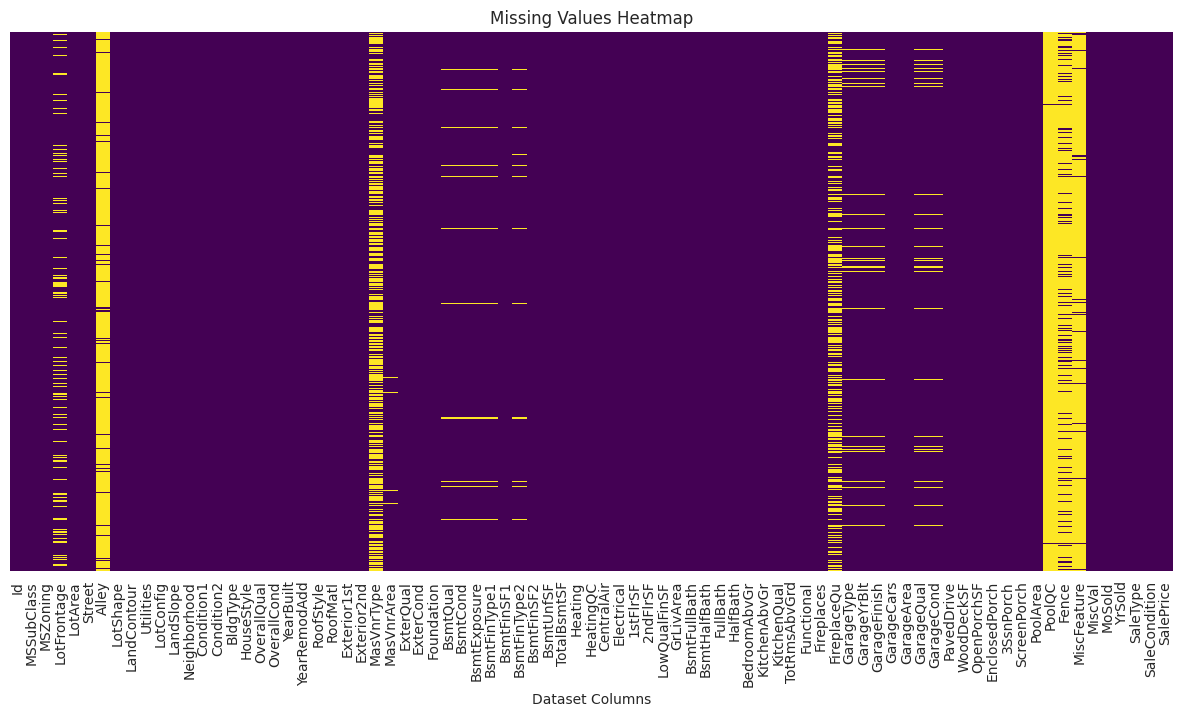

In [66]:
plt.figure(figsize=(15, 7))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values Heatmap')
plt.xlabel('Dataset Columns')

plt.show()

### 8.10 Data Quality Summary

The following data quality checks were performed:

1. Dataset structure and dimensions were examined.
2. Missing values were identified.
3. Missing value percentages were calculated.
4. Duplicate records were checked.
5. Column data types were examined.
6. Unique categorical values were analyzed.
7. Numerical values were validated.
8. Missing value patterns were visualized using a heatmap.

### Conclusion

Data quality analysis helps us understand the reliability and consistency of the dataset.

These checks provide useful information about missing data, duplicate records, data types, and unusual values.

The findings will help us make better decisions during the data cleaning and preprocessing stage.

# 9. Data Cleaning and Preprocessing

In this section, we will clean and preprocess the House Prices dataset.

Data cleaning is an important step in data analysis because it improves data quality and consistency.

We will handle missing values, duplicate records, and unnecessary columns to prepare the dataset for further analysis.

### 9.1 Creating a Copy of the Dataset

We will create a separate copy of the original dataset to preserve the original data during preprocessing.

In [67]:
df_clean = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", df_clean.shape)

Original Dataset Shape: (1460, 81)
Working Dataset Shape: (1460, 81)


### 9.2 Identifying Missing Values

We will calculate the number and percentage of missing values in each column before applying cleaning techniques.

In [68]:
missing_info = pd.DataFrame({
    'Missing Values': df_clean.isnull().sum(),
    'Percentage': (df_clean.isnull().sum() / len(df_clean)) * 100
})

missing_info = missing_info[missing_info['Missing Values'] > 0]

display(missing_info.sort_values(
    by='Percentage',
    ascending=False
))

,Missing Values,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


### 9.3 Removing Duplicate Records

Duplicate records can affect the accuracy of data analysis.

We will identify and remove exact duplicate rows if they exist.

In [69]:
duplicates_before = df_clean.duplicated().sum()

print("Duplicate Records Before Cleaning:", duplicates_before)

df_clean = df_clean.drop_duplicates()

duplicates_after = df_clean.duplicated().sum()

print("Duplicate Records After Cleaning:", duplicates_after)

Duplicate Records Before Cleaning: 0
Duplicate Records After Cleaning: 0


### 9.4 Handling Missing Numerical Values

Missing numerical values will be replaced using the median.

Median is preferred because it is less affected by extreme values and outliers.

In [70]:
numerical_columns = df_clean.select_dtypes(
    include=['int64', 'float64']
).columns

for col in numerical_columns:

    if df_clean[col].isnull().sum() > 0:

        df_clean[col] = df_clean[col].fillna(
            df_clean[col].median()
        )

print("Missing values in numerical columns handled.")

Missing values in numerical columns handled.


### 9.5 Handling Missing Categorical Values

Missing categorical values will be replaced with the most frequent category (mode).

If a column contains only missing values, we will use the label 'Unknown'.

In [71]:
categorical_columns = df_clean.select_dtypes(
    include=['object', 'category']
).columns

for col in categorical_columns:

    if df_clean[col].isnull().sum() > 0:

        mode_values = df_clean[col].mode()

        if not mode_values.empty:
            fill_value = mode_values[0]
        else:
            fill_value = 'Unknown'

        df_clean[col] = df_clean[col].fillna(fill_value)

print("Missing values in categorical columns handled.")

Missing values in categorical columns handled.


### 9.6 Verifying Missing Values After Cleaning

We will check whether any missing values remain after applying the cleaning techniques.

In [72]:
print("Total Missing Values:", df_clean.isnull().sum().sum())

remaining_missing = df_clean.isnull().sum()

display(remaining_missing[remaining_missing > 0])

Total Missing Values: 0


,0


### 9.7 Comparing Original and Cleaned Dataset

We will compare the original dataset with the cleaned dataset to understand the changes made during preprocessing.

In [73]:
comparison = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Total Columns',
        'Missing Values',
        'Duplicate Records'
    ],

    'Original Dataset': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ],

    'Cleaned Dataset': [
        df_clean.shape[0],
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum()
    ]
})

display(comparison)

,Metric,Original Dataset,Cleaned Dataset
0,Total Rows,1460,1460
1,Total Columns,81,81
2,Missing Values,7829,0
3,Duplicate Records,0,0


### 9.8 Cleaned Dataset Information

We will examine the structure and information of the cleaned dataset to verify its quality.

In [74]:
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nCleaned Dataset Information:")
df_clean.info()

print("\nFirst Five Records:")
display(df_clean.head())

Cleaned Dataset Shape: (1460, 81)

Cleaned Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1460 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          1460 non-null   object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   o

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,Grvl,Reg,Lvl,AllPub,...,0,Gd,MnPrv,Shed,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,Grvl,Reg,Lvl,AllPub,...,0,Gd,MnPrv,Shed,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,Grvl,IR1,Lvl,AllPub,...,0,Gd,MnPrv,Shed,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,Grvl,IR1,Lvl,AllPub,...,0,Gd,MnPrv,Shed,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,Grvl,IR1,Lvl,AllPub,...,0,Gd,MnPrv,Shed,0,12,2008,WD,Normal,250000


### 9.9 Missing Values After Cleaning

We will use a heatmap to visualize the missing values in the cleaned dataset.

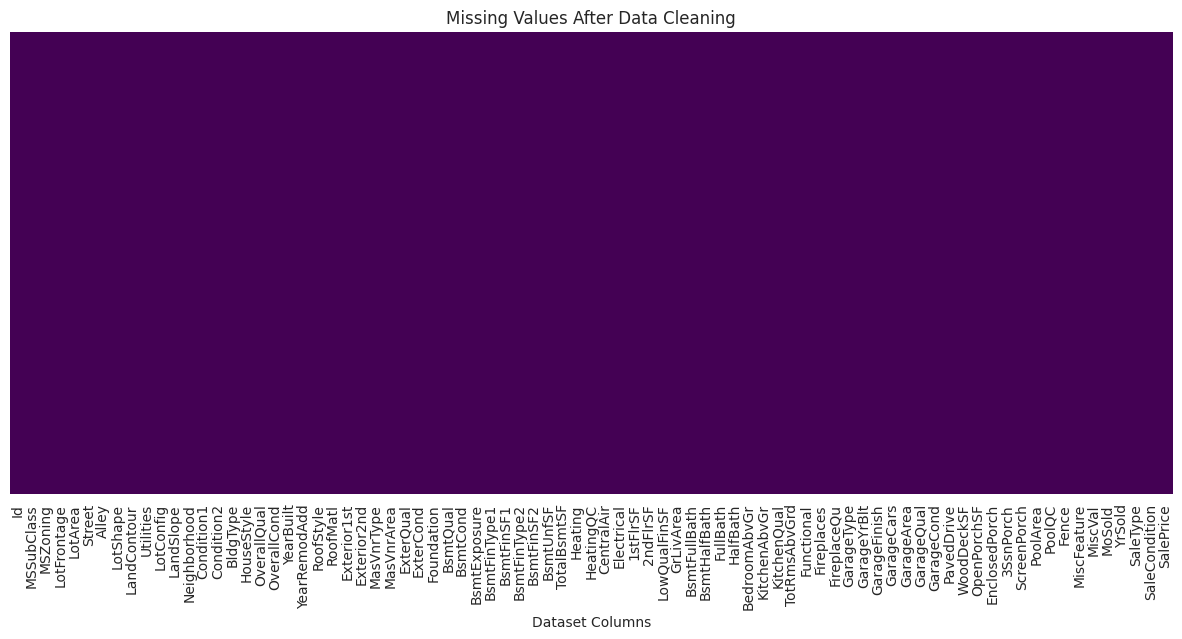

In [75]:
plt.figure(figsize=(15, 6))

sns.heatmap(
    df_clean.isnull(),
    cbar=False,
    yticklabels=False,
    cmap='viridis'
)

plt.title('Missing Values After Data Cleaning')
plt.xlabel('Dataset Columns')

plt.show()

### 9.10 Exporting the Cleaned Dataset

We will export the cleaned dataset into a CSV file so it can be reused in future analysis and machine learning tasks.

In [78]:
df_clean.to_csv(
    'cleaned_house_prices.csv',
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [77]:
from google.colab import files

files.download('cleaned_house_prices.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 9.11 Key Observations

1. A separate copy of the original dataset was created.
2. Duplicate records were identified and removed.
3. Missing numerical values were handled using the median.
4. Missing categorical values were handled using the mode.
5. Remaining missing values were verified.
6. Original and cleaned datasets were compared.
7. The cleaned dataset was exported into CSV format.

### Conclusion

Data cleaning and preprocessing improved the consistency of the House Prices dataset.

The cleaned dataset is now ready for further exploratory analysis and feature engineering.

The original dataset was preserved to avoid accidental data loss.

# 10. Feature Engineering and Feature Selection

In this section, we will perform feature engineering and feature selection on the House Prices dataset.

Feature engineering involves creating new meaningful variables from existing data.

Feature selection helps identify the most useful features for understanding and predicting house prices.

The objective is to improve the quality and usefulness of the dataset.

### 10.1 Understanding Existing Features

We will examine the existing columns to understand which features can be used to create new variables.

In [79]:
print("Total Features:", len(df_clean.columns))

print("\nAvailable Features:")
print(df_clean.columns.tolist())

print("\nDataset Preview:")
display(df_clean.head())

Total Features: 81

Available Features:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPor

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,Grvl,Reg,Lvl,AllPub,...,0,Gd,MnPrv,Shed,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,Grvl,Reg,Lvl,AllPub,...,0,Gd,MnPrv,Shed,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,Grvl,IR1,Lvl,AllPub,...,0,Gd,MnPrv,Shed,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,Grvl,IR1,Lvl,AllPub,...,0,Gd,MnPrv,Shed,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,Grvl,IR1,Lvl,AllPub,...,0,Gd,MnPrv,Shed,0,12,2008,WD,Normal,250000


### 10.2 Creating Total Area Feature

We will combine basement area, first-floor area, and second-floor area to calculate the total house area.

This feature helps us understand the overall size of a house.

In [80]:
df_clean['TotalArea'] = (
    df_clean['TotalBsmtSF'] +
    df_clean['1stFlrSF'] +
    df_clean['2ndFlrSF']
)

display(df_clean[['TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'TotalArea']].head())

,TotalBsmtSF,1stFlrSF,2ndFlrSF,TotalArea
0,856,856,854,2566
1,1262,1262,0,2524
2,920,920,866,2706
3,756,961,756,2473
4,1145,1145,1053,3343


### 10.3 Creating Total Bathrooms Feature

We will combine full bathrooms and half bathrooms from different floors to calculate the total bathroom count.

A half bathroom will be counted as 0.5.

In [81]:
df_clean['TotalBathrooms'] = (
    df_clean['FullBath'] +
    (0.5 * df_clean['HalfBath']) +
    df_clean['BsmtFullBath'] +
    (0.5 * df_clean['BsmtHalfBath'])
)

display(df_clean[['FullBath', 'HalfBath', 'BsmtFullBath', 'BsmtHalfBath', 'TotalBathrooms']].head())

,FullBath,HalfBath,BsmtFullBath,BsmtHalfBath,TotalBathrooms
0,2,1,1,0,3.5
1,2,0,0,1,2.5
2,2,1,1,0,3.5
3,1,0,1,0,2.0
4,2,1,1,0,3.5


### 10.4 Creating House Age Feature

We will calculate the age of each house using the year it was built and the year it was sold.

This feature helps us understand whether house age has any relationship with selling price.

In [82]:
df_clean['HouseAge'] = (
    df_clean['YrSold'] - df_clean['YearBuilt']
)

display(df_clean[['YearBuilt', 'YrSold', 'HouseAge']].head())

,YearBuilt,YrSold,HouseAge
0,2003,2008,5
1,1976,2007,31
2,2001,2008,7
3,1915,2006,91
4,2000,2008,8


### 10.5 Creating Remodeling Age Feature

We will calculate how many years have passed since the house was last remodeled at the time of sale.

This feature can help us understand the impact of renovation on house prices.

In [83]:
df_clean['RemodelAge'] = (
    df_clean['YrSold'] - df_clean['YearRemodAdd']
)

display(df_clean[['YearRemodAdd', 'YrSold', 'RemodelAge']].head())

,YearRemodAdd,YrSold,RemodelAge
0,2003,2008,5
1,1976,2007,31
2,2002,2008,6
3,1970,2006,36
4,2000,2008,8


### 10.6 Creating Total Porch Area

We will combine different porch and outdoor deck areas into one feature.

This helps us understand the total outdoor space available in a house.

In [84]:
porch_columns = [
    'WoodDeckSF',
    'OpenPorchSF',
    'EnclosedPorch',
    '3SsnPorch',
    'ScreenPorch'
]

df_clean['TotalPorchArea'] = df_clean[porch_columns].sum(axis=1)

display(df_clean[porch_columns + ['TotalPorchArea']].head())

,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,TotalPorchArea
0,0,61,0,0,0,61
1,298,0,0,0,0,298
2,0,42,0,0,0,42
3,0,35,272,0,0,307
4,192,84,0,0,0,276


### 10.7 Categorizing House Age

We will divide houses into different age groups to make comparisons easier.

The categories will be:
- New: 0 to 10 years
- Moderate: 11 to 30 years
- Old: 31 to 50 years
- Very Old: More than 50 years

In [85]:
df_clean['HouseAgeCategory'] = pd.cut(
    df_clean['HouseAge'],
    bins=[-1, 10, 30, 50, float('inf')],
    labels=['New', 'Moderate', 'Old', 'Very Old']
)

display(df_clean[['HouseAge', 'HouseAgeCategory']].head(10))

,HouseAge,HouseAgeCategory
0,5,New
1,31,Old
2,7,New
3,91,Very Old
4,8,New
5,16,Moderate
6,3,New
7,36,Old
8,77,Very Old
9,69,Very Old


### 10.8 Analyzing Newly Created Features

We will examine the statistical information of newly created features to understand their distributions.

In [86]:
new_features = [
    'TotalArea',
    'TotalBathrooms',
    'HouseAge',
    'RemodelAge',
    'TotalPorchArea'
]

display(df_clean[new_features].describe())

,TotalArea,TotalBathrooms,HouseAge,RemodelAge,TotalPorchArea
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,2567.048630,2.210616,36.547945,22.950000,181.329452
std,821.714421,0.785399,30.250152,20.640653,156.656097
min,334.000000,1.000000,0.000000,-1.000000,0.000000
25%,2009.500000,2.000000,8.000000,4.000000,45.000000
50%,2474.000000,2.000000,35.000000,14.000000,164.000000
75%,3004.000000,2.500000,54.000000,41.000000,266.000000
max,11752.000000,6.000000,136.000000,60.000000,1027.000000


### 10.9 New Features vs Sale Price

We will visualize the relationships between newly created features and house selling prices using scatter plots.

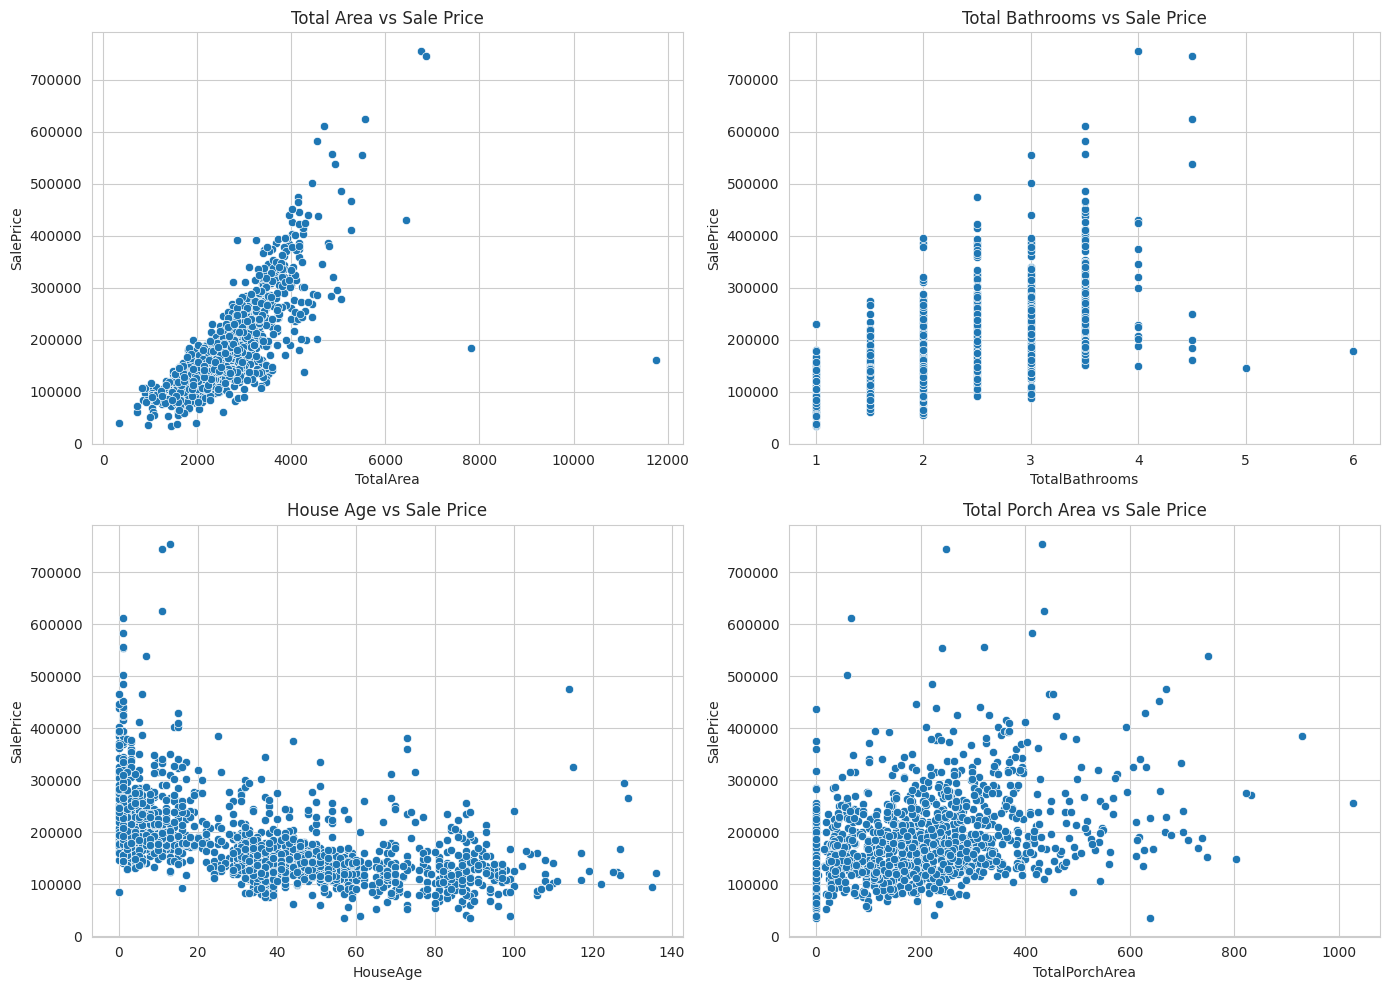

In [87]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.scatterplot(data=df_clean, x='TotalArea', y='SalePrice', ax=axes[0, 0])
axes[0, 0].set_title('Total Area vs Sale Price')

sns.scatterplot(data=df_clean, x='TotalBathrooms', y='SalePrice', ax=axes[0, 1])
axes[0, 1].set_title('Total Bathrooms vs Sale Price')

sns.scatterplot(data=df_clean, x='HouseAge', y='SalePrice', ax=axes[1, 0])
axes[1, 0].set_title('House Age vs Sale Price')

sns.scatterplot(data=df_clean, x='TotalPorchArea', y='SalePrice', ax=axes[1, 1])
axes[1, 1].set_title('Total Porch Area vs Sale Price')

plt.tight_layout()
plt.show()

### 10.10 Correlation Analysis of Important Features

We will calculate correlations between newly created features and SalePrice.

This helps identify features that have stronger linear relationships with house prices.

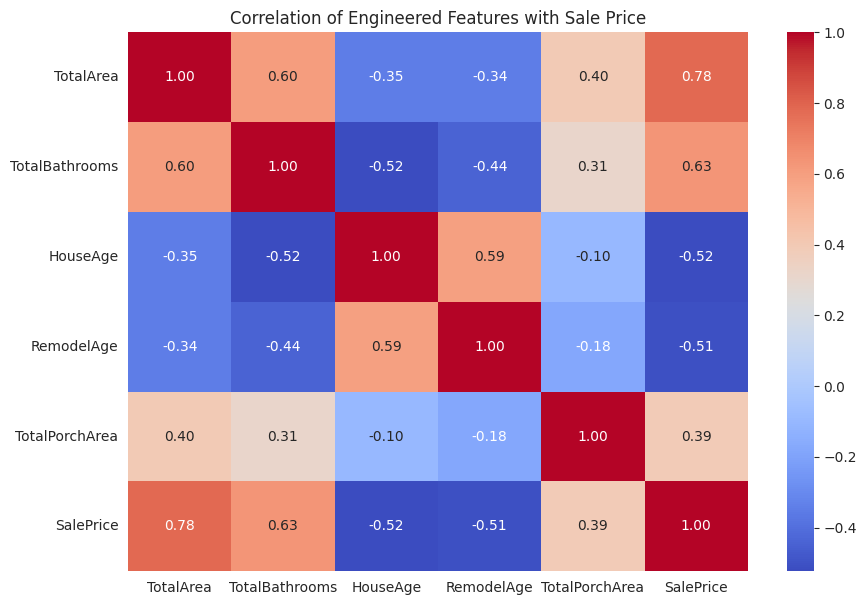

In [88]:
correlation_features = new_features + ['SalePrice']

feature_corr = df_clean[correlation_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    feature_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation of Engineered Features with Sale Price')
plt.show()

### 10.11 Selecting Important Features

We will select important numerical features based on their correlation with SalePrice.

Correlation helps us understand the strength and direction of linear relationships.

In [89]:
saleprice_corr = df_clean.select_dtypes(
    include=['number']
).corr()['SalePrice'].sort_values(ascending=False)

print("Top 15 Features Correlated with SalePrice:")

display(saleprice_corr.head(16))

Top 15 Features Correlated with SalePrice:


,SalePrice
SalePrice,1.000000
OverallQual,0.790982
TotalArea,0.782260
GrLivArea,0.708624
GarageCars,0.640409
TotalBathrooms,0.631731
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664


### 10.12 Visualization of Important Features

We will visualize the top features having the strongest positive correlation with SalePrice.

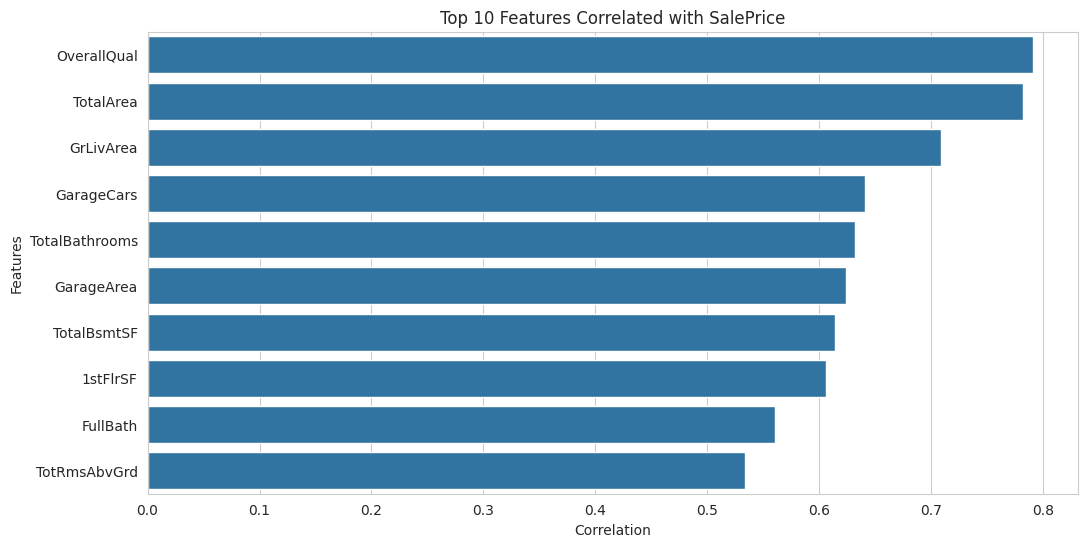

In [90]:
top_features = saleprice_corr.drop('SalePrice').head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_features.values,
    y=top_features.index
)

plt.title('Top 10 Features Correlated with SalePrice')
plt.xlabel('Correlation')
plt.ylabel('Features')

plt.show()

### 10.13 Key Observations

1. TotalArea combines different floor and basement areas.
2. TotalBathrooms represents the combined bathroom availability.
3. HouseAge indicates the age of the property at the time of sale.
4. RemodelAge represents the time since the last remodeling.
5. TotalPorchArea represents the combined outdoor space.
6. Correlation analysis helps identify important numerical features.
7. Feature engineering creates additional information that may help in future predictive analysis.

### Conclusion

Feature engineering and feature selection help improve the usefulness of the dataset.

New features provide additional information about house characteristics.

Correlation analysis helps identify potentially important variables for predicting house prices.

These features can be used in future machine learning tasks.

### 10.14 Exporting the Engineered Dataset

We will save the updated dataset containing the newly created features for future analysis.

In [91]:
df_clean.to_csv(
    'house_prices_feature_engineered.csv',
    index=False
)

print("Feature engineered dataset saved successfully!")

Feature engineered dataset saved successfully!


In [92]:
from google.colab import files

files.download('house_prices_feature_engineered.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 11. Advanced Data Visualization and Insights

In this section, we will perform advanced data visualization to understand different patterns and relationships in the House Prices dataset.

We will use advanced visualization techniques to explore house prices based on quality, neighborhood, house style, and other important features.

The objective is to extract meaningful insights through graphical analysis.

### 11.1 Importing Visualization Libraries

We will import Matplotlib and Seaborn to create advanced visualizations.

In [93]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="viridis")

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


### 11.2 Distribution of Sale Price

We will visualize the distribution of house selling prices using a histogram and KDE curve.

This helps us understand the spread and shape of house prices.

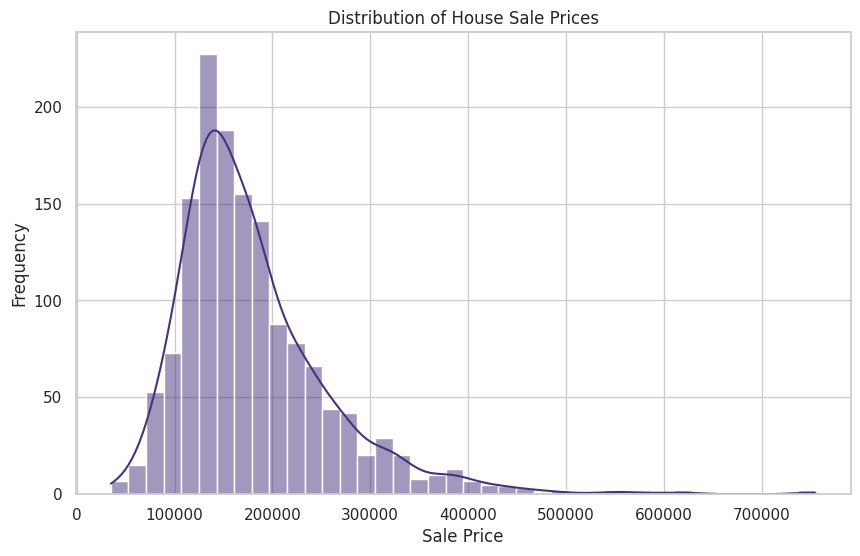

In [94]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean,
    x='SalePrice',
    kde=True,
    bins=40
)

plt.title('Distribution of House Sale Prices')
plt.xlabel('Sale Price')
plt.ylabel('Frequency')

plt.show()

### 11.3 Average Sale Price by Neighborhood

We will compare the average house prices across different neighborhoods.

This visualization helps identify expensive and affordable neighborhoods.

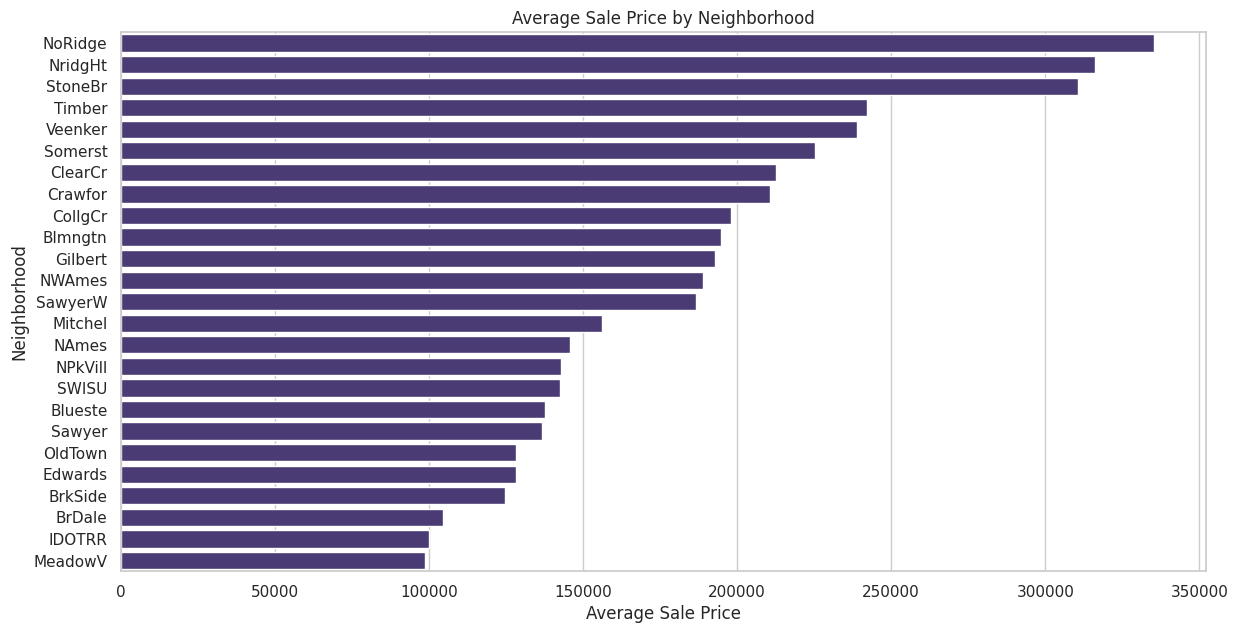

In [95]:
neighborhood_prices = (
    df_clean.groupby('Neighborhood')['SalePrice']
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 7))

sns.barplot(
    x=neighborhood_prices.values,
    y=neighborhood_prices.index
)

plt.title('Average Sale Price by Neighborhood')
plt.xlabel('Average Sale Price')
plt.ylabel('Neighborhood')

plt.show()

### 11.4 Overall Quality vs Sale Price

We will compare house prices across different overall quality ratings.

This helps us understand how construction and material quality relate to selling prices.

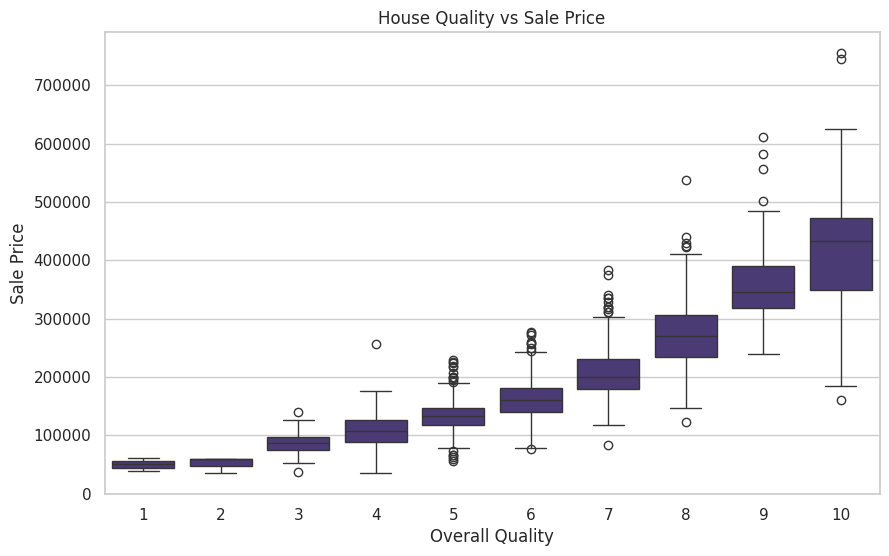

In [96]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_clean,
    x='OverallQual',
    y='SalePrice'
)

plt.title('House Quality vs Sale Price')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')

plt.show()

### 11.5 House Style vs Sale Price

We will analyze how different house styles are associated with selling prices.

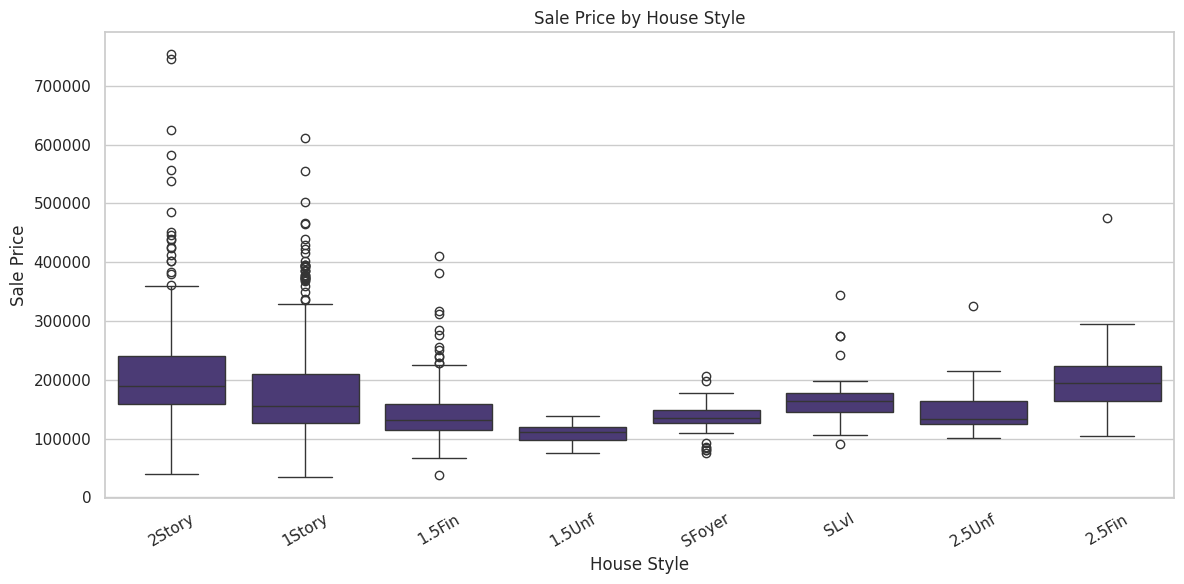

In [97]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_clean,
    x='HouseStyle',
    y='SalePrice'
)

plt.title('Sale Price by House Style')
plt.xlabel('House Style')
plt.ylabel('Sale Price')

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### 11.6 Total Area vs Sale Price

We will analyze the relationship between total house area and selling price using a regression plot.

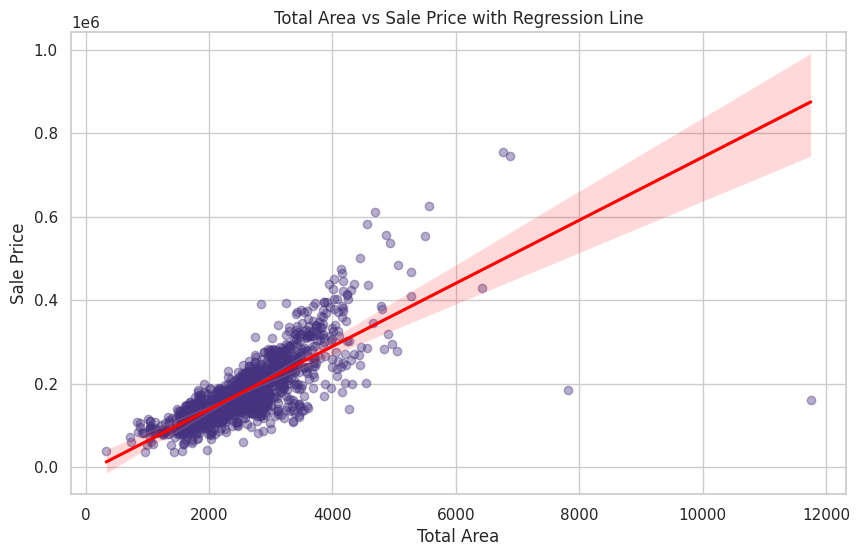

In [98]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='TotalArea',
    y='SalePrice',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Total Area vs Sale Price with Regression Line')
plt.xlabel('Total Area')
plt.ylabel('Sale Price')

plt.show()

### 11.7 Violin Plot of House Quality

A violin plot combines a box plot and distribution visualization.

It helps us understand how sale prices are distributed across different quality ratings.

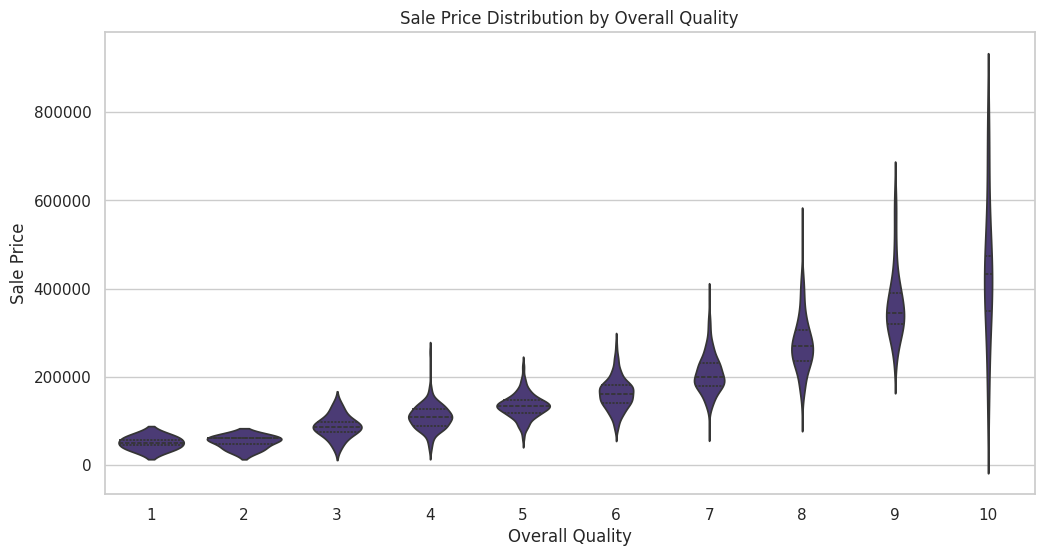

In [99]:
plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df_clean,
    x='OverallQual',
    y='SalePrice',
    inner='quartile'
)

plt.title('Sale Price Distribution by Overall Quality')
plt.xlabel('Overall Quality')
plt.ylabel('Sale Price')

plt.show()

### 11.8 Advanced Correlation Heatmap

We will create a correlation heatmap using important numerical features.

This helps identify strong positive and negative relationships between variables.

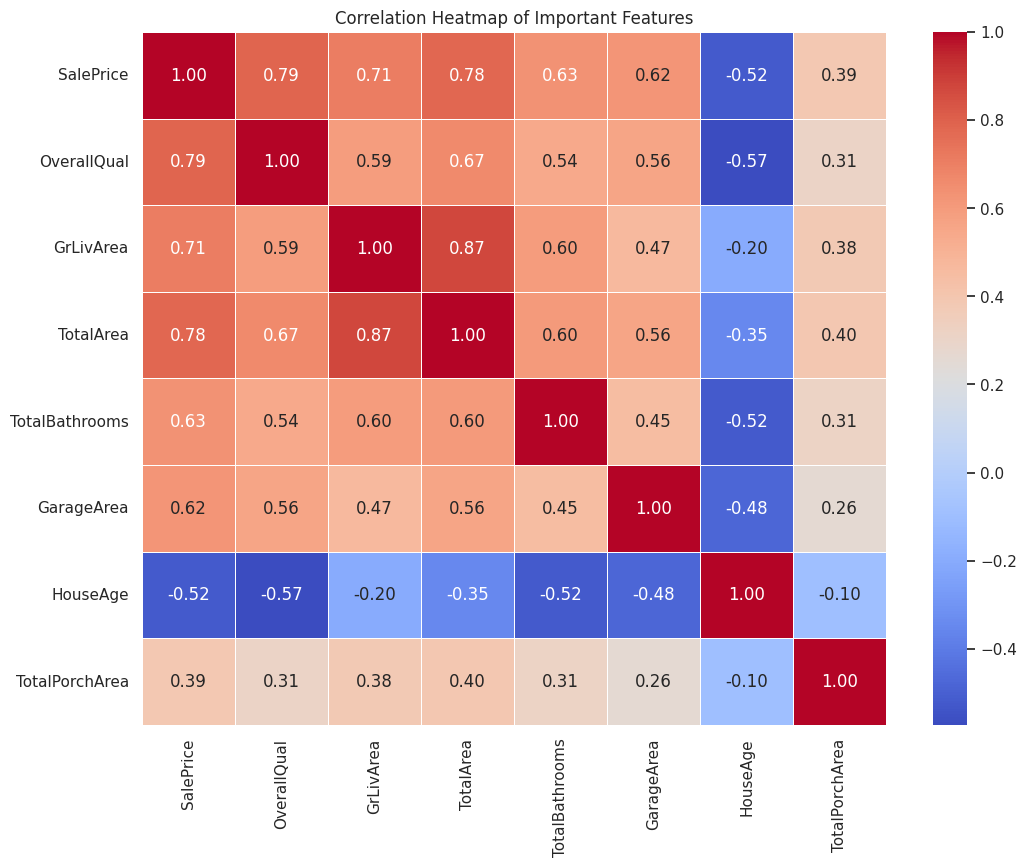

In [100]:
important_features = [
    'SalePrice',
    'OverallQual',
    'GrLivArea',
    'TotalArea',
    'TotalBathrooms',
    'GarageArea',
    'HouseAge',
    'TotalPorchArea'
]

correlation_matrix = df_clean[important_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Important Features')

plt.show()

### 11.9 Average Sale Price by Year

We will compare average house selling prices across different selling years.

This helps us explore price variations over the available sales years.

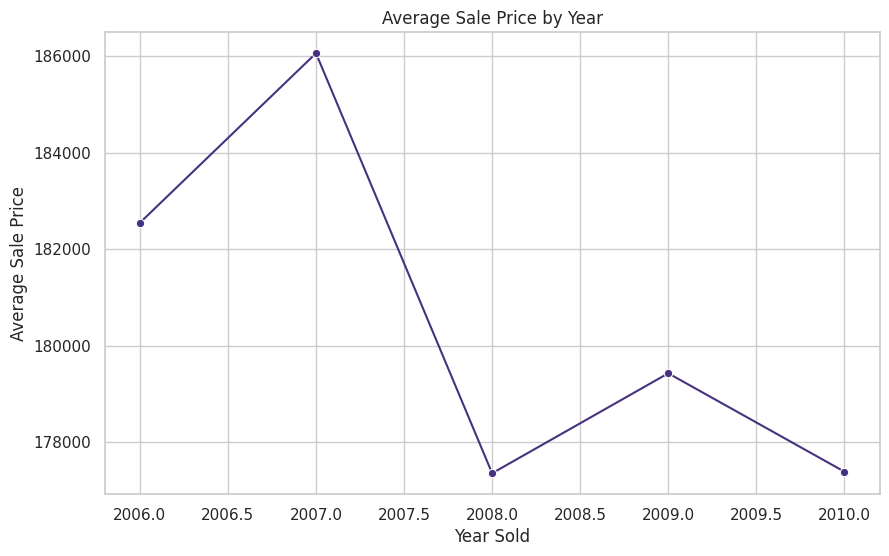

In [101]:
yearly_prices = (
    df_clean.groupby('YrSold')['SalePrice']
    .mean()
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    x=yearly_prices.index,
    y=yearly_prices.values,
    marker='o'
)

plt.title('Average Sale Price by Year')
plt.xlabel('Year Sold')
plt.ylabel('Average Sale Price')

plt.show()

### 11.10 Garage Area vs Sale Price

We will examine whether houses with larger garage areas generally have higher selling prices.

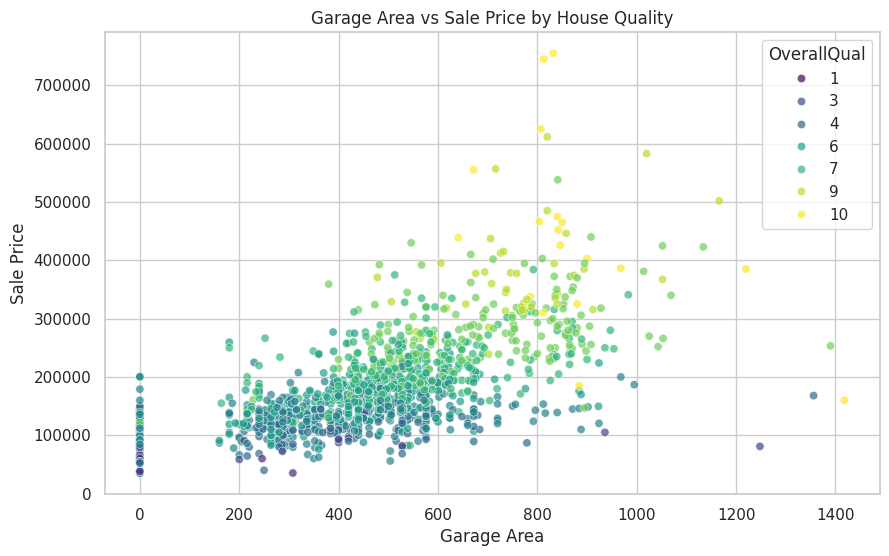

In [102]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='GarageArea',
    y='SalePrice',
    hue='OverallQual',
    palette='viridis',
    alpha=0.7
)

plt.title('Garage Area vs Sale Price by House Quality')
plt.xlabel('Garage Area')
plt.ylabel('Sale Price')

plt.show()

### 11.11 Top 10 Expensive Neighborhoods

We will identify the ten neighborhoods with the highest average house selling prices.

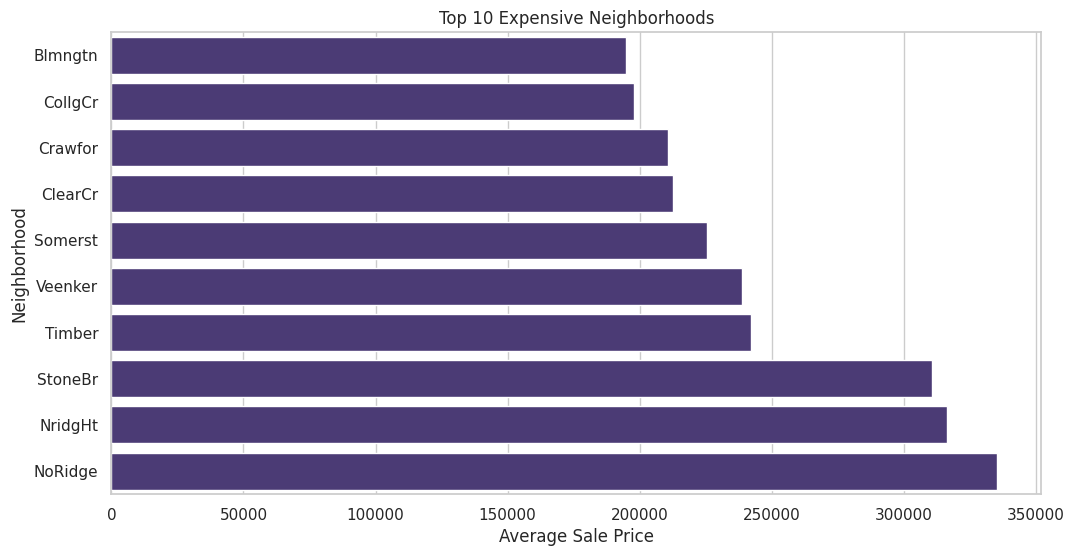

In [103]:
top_neighborhoods = (
    df_clean.groupby('Neighborhood')['SalePrice']
    .mean()
    .nlargest(10)
    .sort_values()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_neighborhoods.values,
    y=top_neighborhoods.index
)

plt.title('Top 10 Expensive Neighborhoods')
plt.xlabel('Average Sale Price')
plt.ylabel('Neighborhood')

plt.show()

### 11.12 Important Data Insights

The following insights will be examined through advanced visualizations:

1. Sale price distribution helps understand the overall pricing pattern.
2. Neighborhood analysis identifies areas with higher average property prices.
3. Overall quality shows how construction quality relates to house prices.
4. House style analysis compares prices across different property designs.
5. Total area helps understand the relationship between property size and price.
6. Violin plots provide information about price distribution across quality levels.
7. Correlation heatmaps identify relationships between numerical features.
8. Yearly analysis helps compare average prices across selling years.
9. Garage area analysis explores its relationship with house prices.
10. Neighborhood ranking identifies locations with higher average selling prices.

### Conclusion

Advanced data visualization provides a deeper understanding of the House Prices dataset.

Different charts help identify patterns, relationships, distributions, and variations in property prices.

These insights can help us understand the important factors associated with house prices.

### 11.13 Exporting the Updated Dataset

We will save the dataset containing all engineered features for future analysis.

In [104]:
df_clean.to_csv(
    'house_prices_advanced_analysis.csv',
    index=False
)

print("Advanced analysis dataset saved successfully!")

Advanced analysis dataset saved successfully!


In [ ]:
from google.colab import files

files.download('house_prices_advanced_analysis.csv')

## 12.1 Importing Libraries for Statistical Analysis

In this section, we import the required Python libraries for descriptive statistics, correlation analysis, and hypothesis testing.

In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

sns.set_theme(style="whitegrid")

## 12.2 Descriptive Statistical Analysis of House Prices

Descriptive statistics help us understand the basic characteristics of house prices, including mean, median, standard deviation, minimum, maximum, and quartiles.

In [106]:
print("Sale Price Statistical Summary:")
print(df_clean['SalePrice'].describe())

print("\nMean Sale Price:", df_clean['SalePrice'].mean())
print("Median Sale Price:", df_clean['SalePrice'].median())
print("Standard Deviation:", df_clean['SalePrice'].std())
print("Minimum Sale Price:", df_clean['SalePrice'].min())
print("Maximum Sale Price:", df_clean['SalePrice'].max())

Sale Price Statistical Summary:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

Mean Sale Price: 180921.19589041095
Median Sale Price: 163000.0
Standard Deviation: 79442.50288288663
Minimum Sale Price: 34900
Maximum Sale Price: 755000


## 12.3 House Price Analysis Based on Overall Quality

OverallQual represents the overall material and finish quality of a house. We group houses by quality rating and compare their average and median sale prices.

In [107]:
quality_analysis = df_clean.groupby('OverallQual')['SalePrice'].agg(
    ['count', 'mean', 'median', 'min', 'max']
)

display(quality_analysis)

,count,mean,median,min,max
OverallQual,,,,,
1,2,50150.000000,50150.0,39300,61000
2,3,51770.333333,60000.0,35311,60000
3,20,87473.750000,86250.0,37900,139600
4,116,108420.655172,108000.0,34900,256000
5,397,133523.347607,133000.0,55993,228950
6,374,161603.034759,160000.0,76000,277000
7,319,207716.423197,200141.0,82500,383970
8,168,274735.535714,269750.0,122000,538000
9,43,367513.023256,345000.0,239000,611657


Code Cell – Visualization:

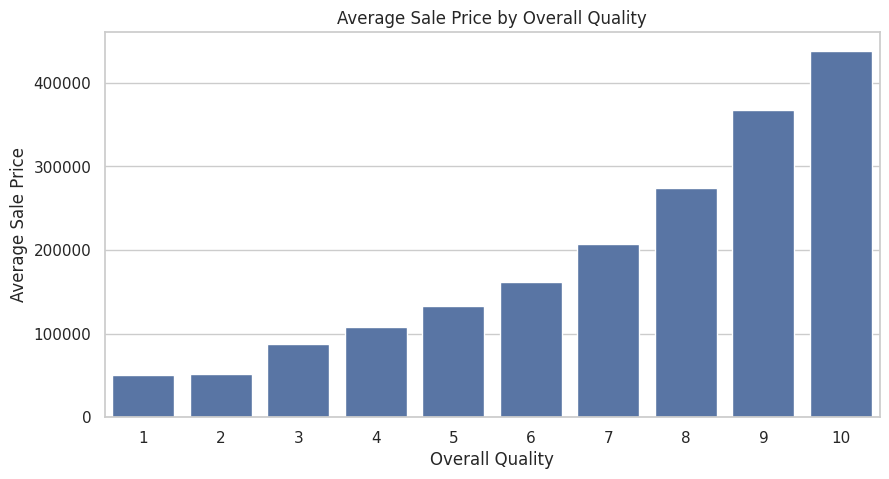

In [108]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_clean,
    x='OverallQual',
    y='SalePrice',
    estimator='mean',
    errorbar=None
)

plt.title("Average Sale Price by Overall Quality")
plt.xlabel("Overall Quality")
plt.ylabel("Average Sale Price")
plt.show()

## 12.4 Normality Analysis of Sale Prices

Normality analysis helps us understand whether the sale price data follows a normal distribution. We use a histogram, KDE curve, and Shapiro-Wilk test.

Histogram:

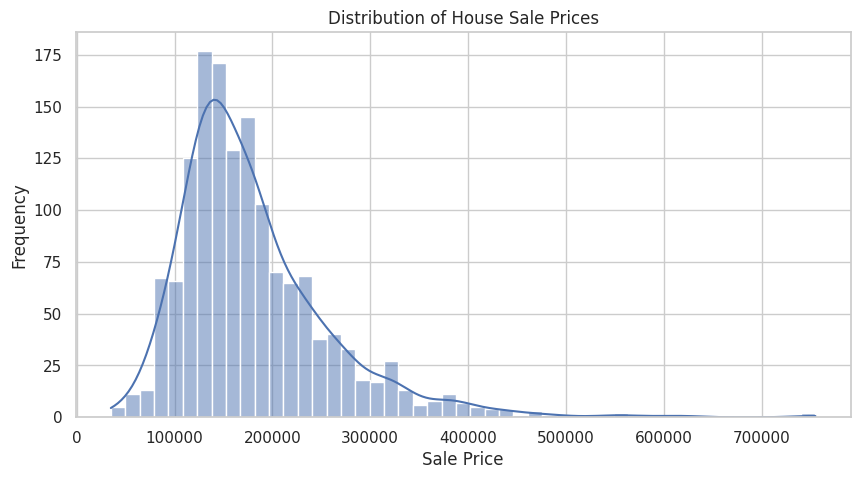

In [109]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean['SalePrice'].dropna(),
    kde=True
)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

Shapiro-Wilk Test:

In [110]:
sale_prices = df_clean['SalePrice'].dropna()

shapiro_stat, shapiro_p = stats.shapiro(sale_prices)

print("Shapiro-Wilk Test Statistic:", shapiro_stat)
print("P-value:", shapiro_p)

if shapiro_p > 0.05:
    print("Result: No strong evidence against normality.")
else:
    print("Result: The data shows evidence of deviation from normality.")

Shapiro-Wilk Test Statistic: 0.8696714665902145
P-value: 3.2061412312021656e-33
Result: The data shows evidence of deviation from normality.


Observation:

* P-value > 0.05: Normality reject karne ke liye sufficient evidence nahi hai.
* P-value ≤ 0.05: Data normal distribution se significantly different ho sakta hai.

Note: Shapiro-Wilk test large datasets mein small deviations ke liye bhi sensitive ho sakta hai. Histogram ko bhi check karna zaroori hai.

## 12.5 Correlation Analysis Between Living Area and Sale Price

We use Pearson and Spearman correlation to understand the relationship between above-ground living area and house sale price.

In [111]:
pearson_corr, pearson_p = stats.pearsonr(
    df_clean['GrLivArea'],
    df_clean['SalePrice']
)

spearman_corr, spearman_p = stats.spearmanr(
    df_clean['GrLivArea'],
    df_clean['SalePrice']
)

print("Pearson Correlation:", pearson_corr)
print("Pearson P-value:", pearson_p)

print("\nSpearman Correlation:", spearman_corr)
print("Spearman P-value:", spearman_p)

Pearson Correlation: 0.7086244776126522
Pearson P-value: 4.518033646776293e-223

Spearman Correlation: 0.7313095834659141
Spearman P-value: 1.4310154533091797e-244


Visualization:

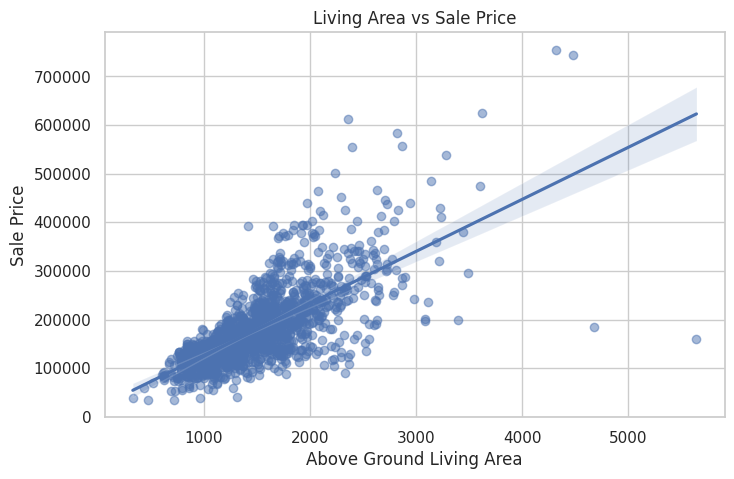

In [112]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_clean,
    x='GrLivArea',
    y='SalePrice',
    scatter_kws={'alpha': 0.5}
)

plt.title("Living Area vs Sale Price")
plt.xlabel("Above Ground Living Area")
plt.ylabel("Sale Price")
plt.show()

Observation: Correlation coefficient positive hai toh dono variables generally same direction mein move karte hain. Correlation causation prove nahi karta.

## 12.6 Hypothesis Testing Using Independent T-Test

We compare the sale prices of high-quality houses and lower-quality houses using an independent two-sample Welch's t-test.

Null Hypothesis (H0): There is no significant difference in the average sale prices of the two groups.

Alternative Hypothesis (H1): There is a significant difference in the average sale prices of the two groups.

Significance Level (Alpha): 0.05

In [113]:
high_quality = df_clean[
    df_clean['OverallQual'] >= 7
]['SalePrice'].dropna()

low_quality = df_clean[
    df_clean['OverallQual'] < 7
]['SalePrice'].dropna()

t_stat, p_value = stats.ttest_ind(
    high_quality,
    low_quality,
    equal_var=False
)

print("High Quality Houses:", len(high_quality))
print("Lower Quality Houses:", len(low_quality))

print("\nHigh Quality Average Price:", high_quality.mean())
print("Lower Quality Average Price:", low_quality.mean())

print("\nT-Statistic:", t_stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("\nConclusion: Reject the Null Hypothesis.")
    print("There is a statistically significant difference in average sale prices.")
else:
    print("\nConclusion: Fail to reject the Null Hypothesis.")
    print("There is not enough evidence of a significant difference.")

High Quality Houses: 548
Lower Quality Houses: 912

High Quality Average Price: 248384.598540146
Lower Quality Average Price: 140383.97587719298

T-Statistic: 28.214084492220817
P-value: 1.8445147442018486e-116

Conclusion: Reject the Null Hypothesis.
There is a statistically significant difference in average sale prices.


## 12.7 One-Way ANOVA – Comparing Prices Across Quality Groups

ANOVA (Analysis of Variance) is used to compare the average sale prices of three or more independent groups.

Null Hypothesis (H0): All selected quality groups have equal average sale prices.

Alternative Hypothesis (H1): At least one group has a different average sale price.

In [114]:
quality_groups = []

for quality in [5, 6, 7, 8]:
    group = df_clean[
        df_clean['OverallQual'] == quality
    ]['SalePrice'].dropna()

    if len(group) > 0:
        quality_groups.append(group)

f_stat, anova_p = stats.f_oneway(*quality_groups)

print("ANOVA F-Statistic:", f_stat)
print("ANOVA P-value:", anova_p)

if anova_p < 0.05:
    print("\nConclusion: Reject the Null Hypothesis.")
    print("At least one quality group has a significantly different average price.")
else:
    print("\nConclusion: Fail to reject the Null Hypothesis.")
    print("There is not enough evidence of a difference between group averages.")

ANOVA F-Statistic: 548.0064095536152
ANOVA P-value: 1.6733177050291058e-227

Conclusion: Reject the Null Hypothesis.
At least one quality group has a significantly different average price.


 Visualization:

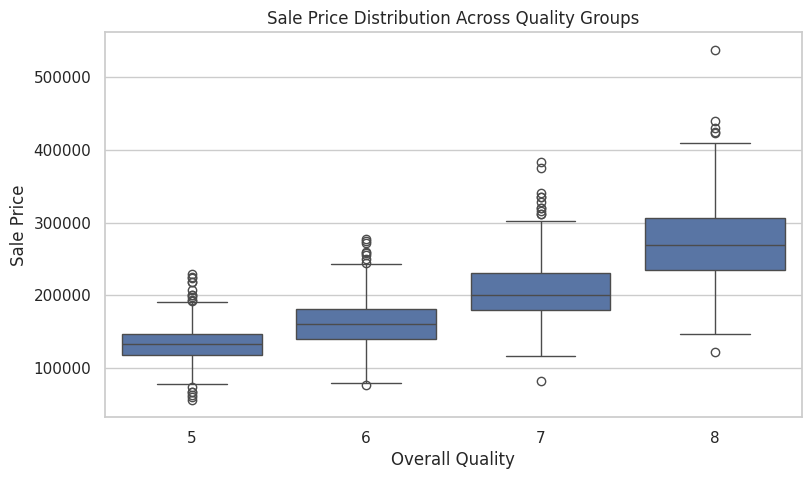

In [115]:
anova_data = df_clean[
    df_clean['OverallQual'].isin([5, 6, 7, 8])
]

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=anova_data,
    x='OverallQual',
    y='SalePrice'
)

plt.title("Sale Price Distribution Across Quality Groups")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")
plt.show()

Observation: ANOVA significant hone ka matlab hai ki at least ek group ka mean different hai. Kaunse specific groups different hain, ye jaanne ke liye additional post-hoc test ki zaroorat hoti hai.

## 12.8 Statistical Summary of House Price Analysis

In this section, we summarize the major statistical results obtained from the dataset.

In [116]:
statistical_summary = pd.DataFrame({
    'Metric': [
        'Mean Sale Price',
        'Median Sale Price',
        'Standard Deviation',
        'Pearson Correlation',
        'Spearman Correlation',
        'Shapiro-Wilk P-value',
        'T-Test P-value',
        'ANOVA P-value'
    ],
    'Value': [
        df_clean['SalePrice'].mean(),
        df_clean['SalePrice'].median(),
        df_clean['SalePrice'].std(),
        pearson_corr,
        spearman_corr,
        shapiro_p,
        p_value,
        anova_p
    ]
})

display(statistical_summary)

,Metric,Value
0,Mean Sale Price,1.809212e+05
1,Median Sale Price,1.630000e+05
2,Standard Deviation,7.944250e+04
3,Pearson Correlation,7.086245e-01
4,Spearman Correlation,7.313096e-01
5,Shapiro-Wilk P-value,3.206141e-33
6,T-Test P-value,1.844515e-116
7,ANOVA P-value,1.673318e-227


## 12.9 Exporting Statistical Analysis Results

We export the statistical summary into a CSV file for future reference and reporting.

In [117]:
statistical_summary.to_csv(
    'house_prices_statistical_summary.csv',
    index=False
)

print("Statistical summary exported successfully!")

Statistical summary exported successfully!


In [118]:
statistical_summary.to_csv(
    'house_prices_statistical_summary.csv',
    index=False
)

print("Statistical summary exported successfully!")

Statistical summary exported successfully!


## 12.10 Final Observations and Conclusion

1. Descriptive statistics helped us understand the distribution and variation in house sale prices.
2. Overall quality analysis helped us compare prices across different quality ratings.
3. Normality testing provided information about whether sale prices follow a normal distribution.
4. Pearson and Spearman correlation helped us understand the relationship between living area and sale price.
5. The independent t-test compared the average prices of high-quality and lower-quality houses.
6. One-way ANOVA helped us compare average prices across multiple quality groups.

Overall, statistical analysis provides a deeper understanding of the House Prices dataset and helps identify important relationships between house features and sale prices.

# PART 13 – Final EDA Report, Key Findings and Business Insights

## Project Overview

The objective of this project is to perform Exploratory Data Analysis (EDA) on the House Prices dataset.

The analysis focuses on understanding house price distributions, identifying important features, detecting outliers, handling missing values, performing feature engineering, and discovering relationships between different house characteristics and sale prices.

The final goal is to extract meaningful insights that can help understand the factors influencing house prices.

## 13.1 Final Dataset Overview

In this section, we examine the final cleaned dataset to understand its dimensions, data types, and overall structure.

In [119]:
print("Final Dataset Shape:", df_clean.shape)

print("\nDataset Information:")
df_clean.info()

print("\nFirst 5 Rows:")
display(df_clean.head())

print("\nStatistical Summary:")
display(df_clean.describe())

Final Dataset Shape: (1460, 87)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 87 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Id                1460 non-null   int64   
 1   MSSubClass        1460 non-null   int64   
 2   MSZoning          1460 non-null   object  
 3   LotFrontage       1460 non-null   float64 
 4   LotArea           1460 non-null   int64   
 5   Street            1460 non-null   object  
 6   Alley             1460 non-null   object  
 7   LotShape          1460 non-null   object  
 8   LandContour       1460 non-null   object  
 9   Utilities         1460 non-null   object  
 10  LotConfig         1460 non-null   object  
 11  LandSlope         1460 non-null   object  
 12  Neighborhood      1460 non-null   object  
 13  Condition1        1460 non-null   object  
 14  Condition2        1460 non-null   object  
 15  BldgType          

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,YrSold,SaleType,SaleCondition,SalePrice,TotalArea,TotalBathrooms,HouseAge,RemodelAge,TotalPorchArea,HouseAgeCategory
0,1,60,RL,65.0,8450,Pave,Grvl,Reg,Lvl,AllPub,...,2008,WD,Normal,208500,2566,3.5,5,5,61,New
1,2,20,RL,80.0,9600,Pave,Grvl,Reg,Lvl,AllPub,...,2007,WD,Normal,181500,2524,2.5,31,31,298,Old
2,3,60,RL,68.0,11250,Pave,Grvl,IR1,Lvl,AllPub,...,2008,WD,Normal,223500,2706,3.5,7,6,42,New
3,4,70,RL,60.0,9550,Pave,Grvl,IR1,Lvl,AllPub,...,2006,WD,Abnorml,140000,2473,2.0,91,36,307,Very Old
4,5,60,RL,84.0,14260,Pave,Grvl,IR1,Lvl,AllPub,...,2008,WD,Normal,250000,3343,3.5,8,8,276,New



Statistical Summary:


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,PoolArea,MiscVal,MoSold,YrSold,SalePrice,TotalArea,TotalBathrooms,HouseAge,RemodelAge,TotalPorchArea
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,69.863699,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.117123,443.639726,...,2.758904,43.489041,6.321918,2007.815753,180921.195890,2567.048630,2.210616,36.547945,22.950000,181.329452
std,421.610009,42.300571,22.027677,9981.264932,1.382997,1.112799,30.202904,20.645407,180.731373,456.098091,...,40.177307,496.123024,2.703626,1.328095,79442.502883,821.714421,0.785399,30.250152,20.640653,156.656097
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,1.000000,2006.000000,34900.000000,334.000000,1.000000,0.000000,-1.000000,0.000000
25%,365.750000,20.000000,60.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,5.000000,2007.000000,129975.000000,2009.500000,2.000000,8.000000,4.000000,45.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,0.000000,6.000000,2008.000000,163000.000000,2474.000000,2.000000,35.000000,14.000000,164.000000
75%,1095.250000,70.000000,79.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,164.250000,712.250000,...,0.000000,0.000000,8.000000,2009.000000,214000.000000,3004.000000,2.500000,54.000000,41.000000,266.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,738.000000,15500.000000,12.000000,2010.000000,755000.000000,11752.000000,6.000000,136.000000,60.000000,1027.000000


## 13.2 Final Data Quality Verification

We verify whether missing values and duplicate records remain in the cleaned dataset.

In [120]:
print("Total Missing Values:", df_clean.isnull().sum().sum())

print("\nMissing Values by Column:")
display(
    df_clean.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

print("\nDuplicate Rows:", df_clean.duplicated().sum())

Total Missing Values: 0

Missing Values by Column:


,0
Id,0
MSSubClass,0
MSZoning,0
LotFrontage,0
LotArea,0
Street,0
Alley,0
LotShape,0
LandContour,0
Utilities,0



Duplicate Rows: 0


## 13.3 Important Features Affecting Sale Price

We identify numerical features that have the strongest correlation with SalePrice.

Correlation helps us understand the strength and direction of relationships between numerical variables.

In [121]:
correlation = df_clean.corr(numeric_only=True)['SalePrice']

top_features = (
    correlation.drop('SalePrice')
    .sort_values(key=abs, ascending=False)
    .head(10)
)

print("Top 10 Features Related to SalePrice:")
display(top_features)

Top 10 Features Related to SalePrice:


,SalePrice
OverallQual,0.790982
TotalArea,0.782260
GrLivArea,0.708624
GarageCars,0.640409
TotalBathrooms,0.631731
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723


Visualization:

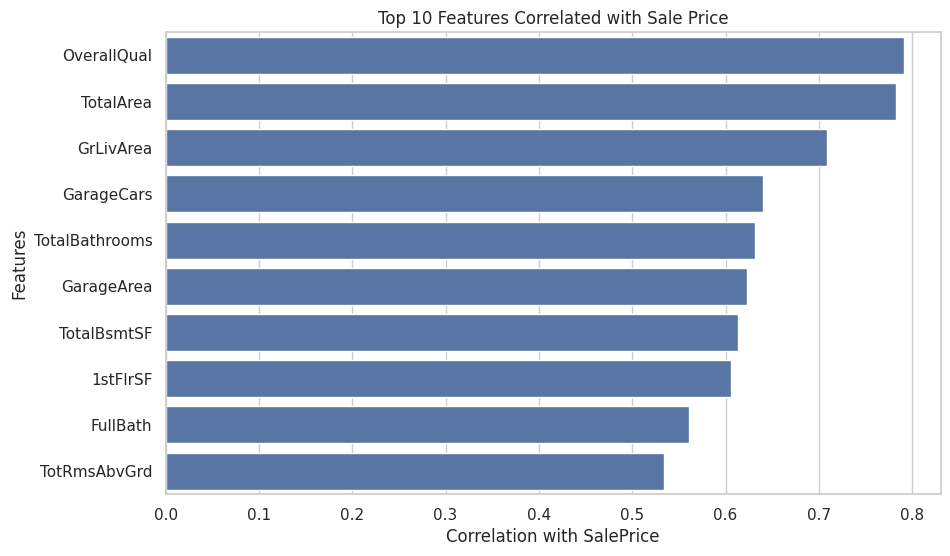

In [122]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_features.values,
    y=top_features.index
)

plt.title("Top 10 Features Correlated with Sale Price")
plt.xlabel("Correlation with SalePrice")
plt.ylabel("Features")
plt.show()

## 13.4 Final House Price Distribution

We visualize the distribution of sale prices to understand the price range and identify whether the distribution is symmetric or skewed.

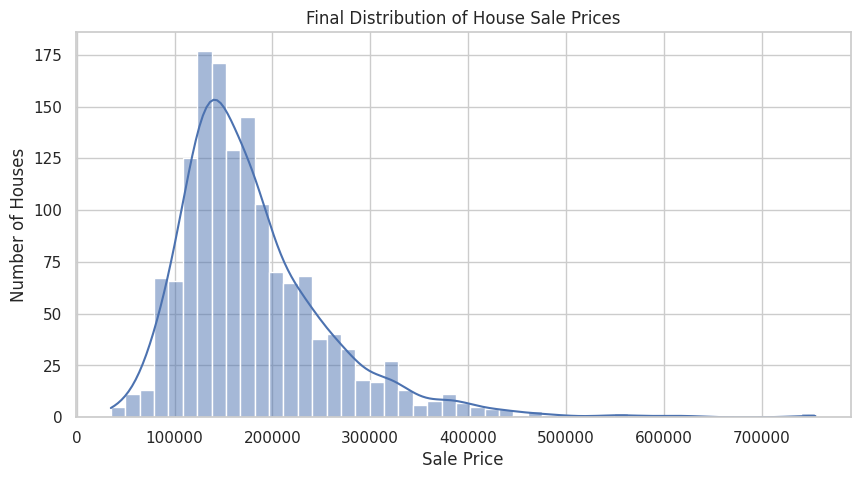

In [123]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean['SalePrice'],
    kde=True
)

plt.title("Final Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.show()

## 13.5 Neighborhood-Wise Business Analysis

We compare average house sale prices across different neighborhoods to identify areas with relatively higher and lower average prices.

In [124]:
neighborhood_prices = (
    df_clean.groupby('Neighborhood')['SalePrice']
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 Expensive Neighborhoods:")
display(neighborhood_prices.head(10))

print("\nTop 10 Lower Average Price Neighborhoods:")
display(neighborhood_prices.tail(10))

Top 10 Expensive Neighborhoods:


,SalePrice
Neighborhood,
NoRidge,335295.317073
NridgHt,316270.623377
StoneBr,310499.000000
Timber,242247.447368
Veenker,238772.727273
Somerst,225379.837209
ClearCr,212565.428571
Crawfor,210624.725490
CollgCr,197965.773333



Top 10 Lower Average Price Neighborhoods:


,SalePrice
Neighborhood,
NPkVill,142694.444444
SWISU,142591.360000
Blueste,137500.000000
Sawyer,136793.135135
OldTown,128225.300885
Edwards,128219.700000
BrkSide,124834.051724
BrDale,104493.750000
IDOTRR,100123.783784


 Visualization:

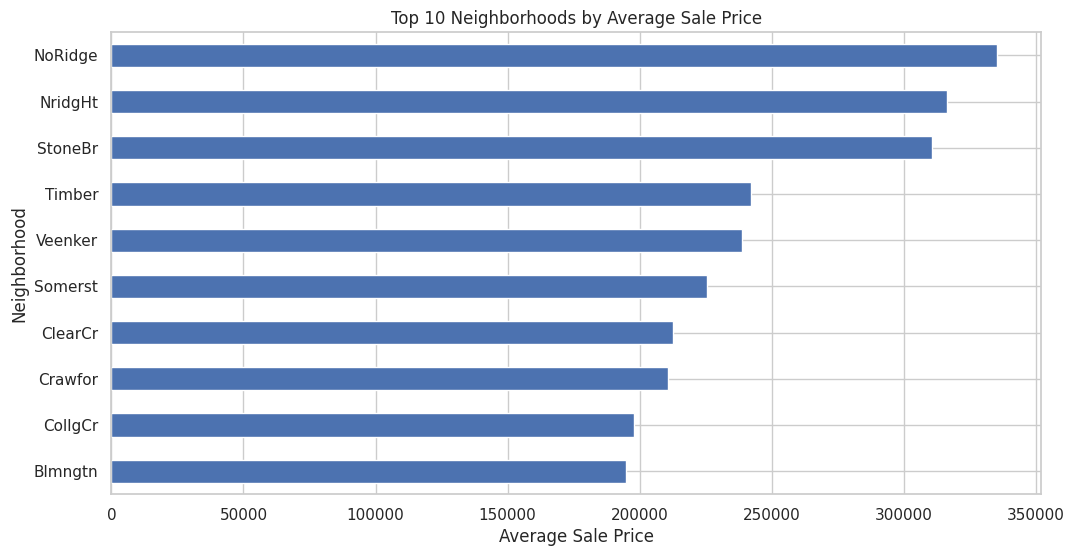

In [125]:
plt.figure(figsize=(12, 6))

neighborhood_prices.head(10).sort_values().plot(
    kind='barh'
)

plt.title("Top 10 Neighborhoods by Average Sale Price")
plt.xlabel("Average Sale Price")
plt.ylabel("Neighborhood")
plt.show()

Observation: Top neighborhoods aur lower average price wale neighborhoods identify karo. Average price alone har individual property ki value determine nahi karta.

## 13.6 Relationship Between Overall Quality and Sale Price

We analyze how the overall quality of a house is associated with its sale price.

In [126]:
quality_prices = (
    df_clean.groupby('OverallQual')['SalePrice']
    .mean()
    .reset_index()
)

display(quality_prices)

,OverallQual,SalePrice
0,1,50150.000000
1,2,51770.333333
2,3,87473.750000
3,4,108420.655172
4,5,133523.347607
5,6,161603.034759
6,7,207716.423197
7,8,274735.535714
8,9,367513.023256
9,10,438588.388889


Visualization:

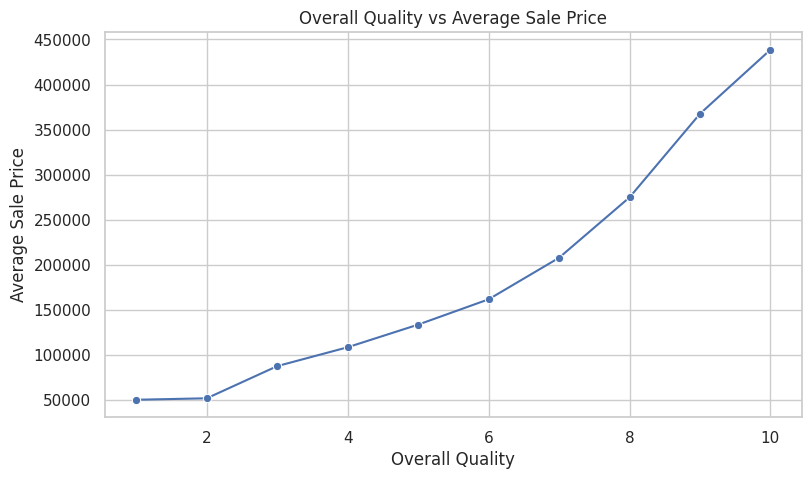

In [127]:
plt.figure(figsize=(9, 5))

sns.lineplot(
    data=quality_prices,
    x='OverallQual',
    y='SalePrice',
    marker='o'
)

plt.title("Overall Quality vs Average Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Average Sale Price")
plt.show()

## 13.7 Comparison of Important House Features

We compare important house features such as total area, bathrooms, garage area, and house age with sale price.

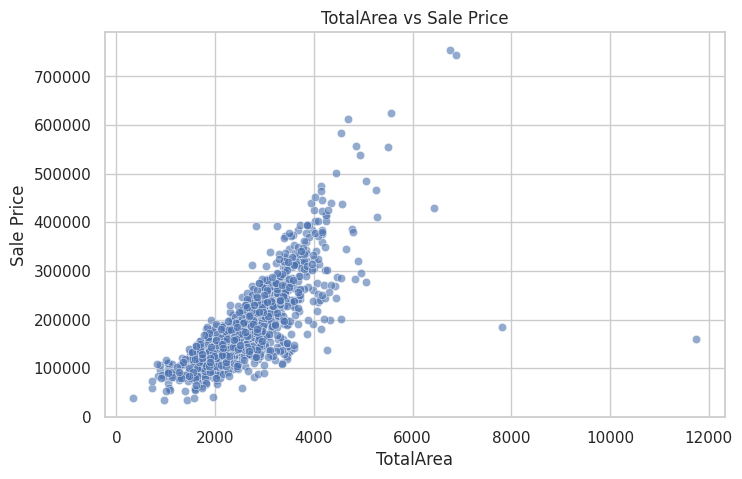

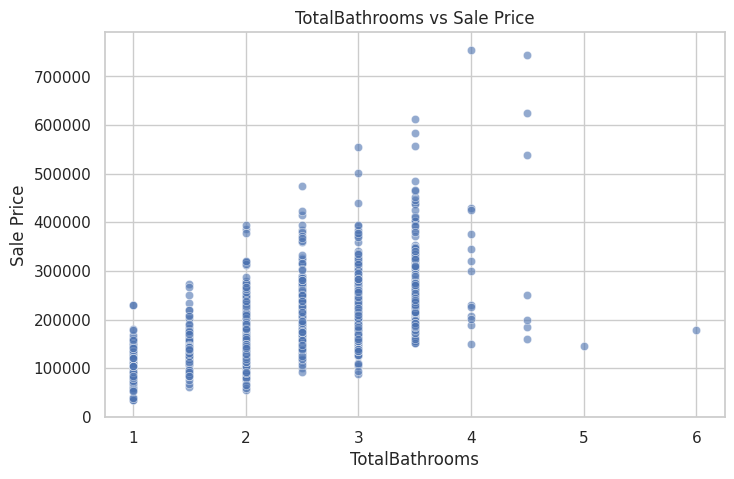

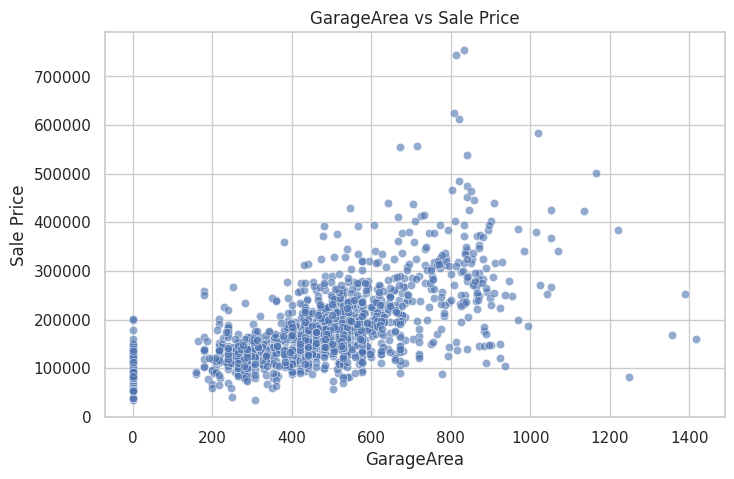

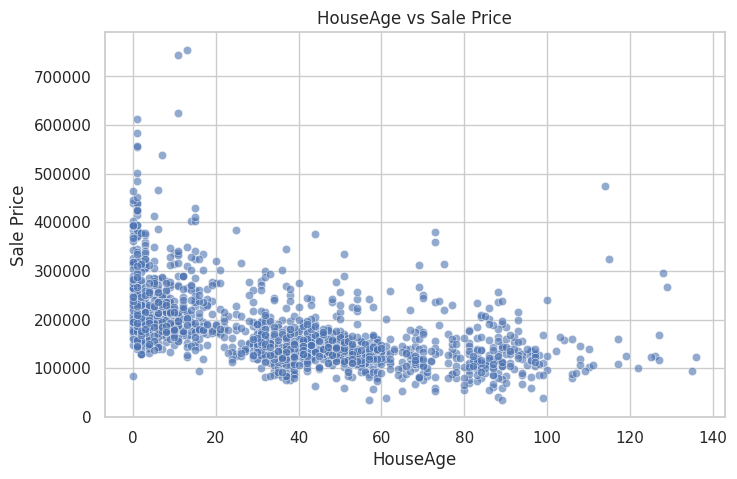

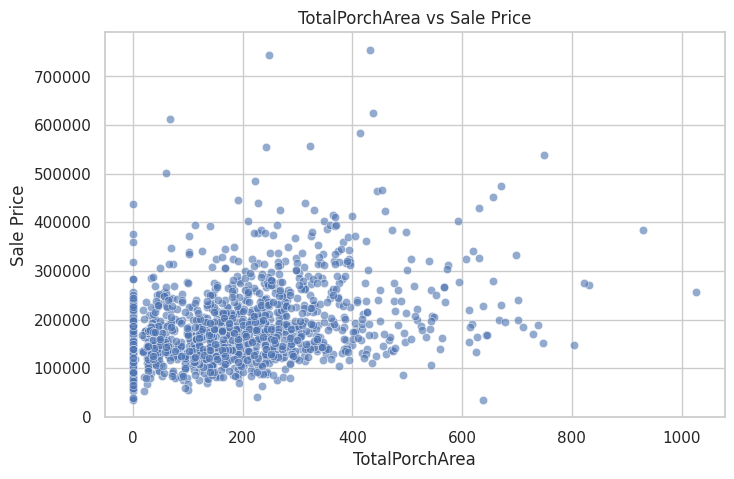

In [128]:
important_features = [
    'TotalArea',
    'TotalBathrooms',
    'GarageArea',
    'HouseAge',
    'TotalPorchArea'
]

for feature in important_features:

    if feature in df_clean.columns:

        plt.figure(figsize=(8, 5))

        sns.scatterplot(
            data=df_clean,
            x=feature,
            y='SalePrice',
            alpha=0.6
        )

        plt.title(f'{feature} vs Sale Price')
        plt.xlabel(feature)
        plt.ylabel('Sale Price')
        plt.show()

## 13.8 Key Findings of Exploratory Data Analysis

The following points summarize the major areas explored during this project:

1. House sale prices show variation across different properties.
2. Overall quality is an important feature to investigate when understanding house prices.
3. Living area and total house area help explain differences in property prices.
4. Neighborhood location provides useful information about average property prices.
5. Outlier analysis helps identify unusually priced or unusually sized houses.
6. Data cleaning improves the quality and consistency of the dataset.
7. Feature engineering creates additional variables that can provide useful information.
8. Statistical analysis helps evaluate relationships and differences between house price groups.

Note: These are general findings from the analysis process. Update them according to the actual results obtained from the dataset.

## 13.9 Business Insights and Recommendations

Based on the exploratory analysis, the following business insights can be considered:

1. Property buyers can compare neighborhoods based on average sale prices.
2. Real estate agents can consider house quality and living area while evaluating properties.
3. Property sellers can use similar property characteristics to understand market positioning.
4. Investors can investigate neighborhoods with different price ranges to identify potential opportunities.
5. Real estate platforms can use property features to build better price comparison systems.
6. Further predictive modeling can help estimate house prices using important property features.

EDA provides useful insights, but these findings should not be treated as guaranteed property valuations or investment recommendations.

## 13.10 Generating Final EDA Summary Report

We create a summary report containing the main dataset information, house price statistics, data quality information, and important correlations.

In [129]:
final_report = pd.DataFrame({
    'Metric': [
        'Total Records',
        'Total Features',
        'Missing Values',
        'Duplicate Rows',
        'Average Sale Price',
        'Median Sale Price',
        'Minimum Sale Price',
        'Maximum Sale Price',
        'Standard Deviation of Sale Price'
    ],

    'Value': [
        df_clean.shape[0],
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        df_clean['SalePrice'].mean(),
        df_clean['SalePrice'].median(),
        df_clean['SalePrice'].min(),
        df_clean['SalePrice'].max(),
        df_clean['SalePrice'].std()
    ]
})

display(final_report)

,Metric,Value
0,Total Records,1460.000000
1,Total Features,87.000000
2,Missing Values,0.000000
3,Duplicate Rows,0.000000
4,Average Sale Price,180921.195890
5,Median Sale Price,163000.000000
6,Minimum Sale Price,34900.000000
7,Maximum Sale Price,755000.000000
8,Standard Deviation of Sale Price,79442.502883


## 13.11 Exporting the Final EDA Report

We export the final EDA summary and important feature correlations into separate CSV files for documentation and future reference.

In [130]:
final_report.to_csv(
    'final_house_prices_eda_report.csv',
    index=False
)

top_features.to_csv(
    'top_house_price_correlations.csv',
    header=['Correlation']
)

print("Final EDA reports exported successfully!")

Final EDA reports exported successfully!


In [131]:
from google.colab import files

files.download('final_house_prices_eda_report.csv')
files.download('top_house_price_correlations.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 13.12 Final Project Conclusion

In this project, Exploratory Data Analysis was performed on the House Prices dataset using Python.

The project included data loading, data inspection, variable classification, numerical and categorical analysis, data visualization, correlation analysis, outlier detection, data quality checks, data cleaning, feature engineering, statistical analysis, and business insights.

Libraries such as Pandas, NumPy, Matplotlib, Seaborn, and SciPy were used to analyze and visualize the dataset.

The analysis helped us understand how different property characteristics are associated with house sale prices.

This project provided practical experience in data analysis, data preprocessing, visualization, statistical testing, and extracting meaningful insights from real-world datasets.

The final cleaned dataset and EDA reports can also be used as a starting point for future machine learning models that predict house prices.